# ANALÍTICA EMPRESARIAL INTEGRADA
## LABORATORIO DIRIGIDO N.° 10 — Pronóstico de demanda

**Semana 10 · TECSUP 2026-II**
**Docente:** PILAR ROCIO SAYAN MEJIA
**Dataset real:** Online Retail II — UCI Machine Learning Repository (ID 502)
**Objetivo:** construir un pronóstico semanal de ventas, seleccionar modelo y política de cantidad con validación temporal sin información futura, evaluarlos una sola vez y decidir si conviene adoptarlos.

> El notebook termina en una **decisión fundamentada** (adoptar, mantener en evaluación o no adoptar), no solo en el modelo con menor error.

## Trabajo individual y entrega

Esta práctica dirigida es **individual**. Ejecute el notebook en **su propio Google Colab**, verifique los resultados y responda con sus propias interpretaciones. No se requiere informe separado: las respuestas, el cierre ejecutivo y las conclusiones quedan en este notebook.

**Al final de la sesión:**
1. Suba este notebook, ejecutado y con los retos resueltos, a la carpeta `semana10/` de su repositorio personal de GitHub.
2. Conserve la versión en su propio Google Colab y compártala con permiso de lectura.
3. En la **actividad de la semana** presente **ambos URLs**: el enlace directo al archivo en GitHub y el enlace a su Colab.

**Identificación**
- Nombre: Jhadir Abdel Yupanqui Chahua.
- Sección: C28 6to A-L.
- URL de GitHub: [notebook ejecutado en semana10/](https://github.com/jhadir08/analitica-empresarial-integrada/blob/main/semana10/LAB-D10-AEI-PSAYAN-2026-02_YUPANQUI.ipynb).
- URL para abrir en Colab: [abrir la versión de GitHub](https://colab.research.google.com/github/jhadir08/analitica-empresarial-integrada/blob/main/semana10/LAB-D10-AEI-PSAYAN-2026-02_YUPANQUI.ipynb). Es un enlace de apertura; no acredita una copia guardada en Google Drive.
- Uso de IA declarado: se utilizó Codex (OpenAI) para implementar los apartados, ejecutar el código, revisar los resultados y redactar respuestas basadas en las salidas. Las 28 celdas se ejecutaron localmente con Python 3.12.10 el 23/10/2026 (America/Lima).

**Alcance de esta entrega:** notebook completo, ejecutado y publicado en GitHub. No se ha registrado una entrega en Canvas ni se ha creado una copia personal en Drive.


# 1. Pregunta de negocio

**¿Cuántas unidades debería planificar la empresa para las próximas semanas, qué riesgo asume si el pronóstico se equivoca y conviene adoptar el modelo?**

Se distinguen cuatro pasos que no deben confundirse:
1. **Pronóstico de ventas:** estimación de las ventas semanales.
2. **Política de cantidad:** regla que convierte el pronóstico en una cantidad objetivo semanal (pronóstico + colchón).
3. **Evaluación económica:** costo de los excedentes y faltantes que produce esa política.
4. **Decisión de adopción:** usar, mantener en evaluación o no usar el modelo, según su resultado frente al baseline.

### Diseño del laboratorio
| Elemento | Definición |
|---|---|
| Unidad temporal | Semana de lunes a domingo, identificada por la fecha del lunes |
| Semanas válidas | Solo semanas completas según la cobertura del archivo |
| Variable objetivo | Unidades vendidas (registradas) por semana de un SKU del Reino Unido |
| Test final | Últimas 8 semanas completas; se evalúa una sola vez |
| Selección del SKU | Criterios calculados solo antes del test |
| Validación | Backtesting rolling-origin con horizonte de 8 semanas dentro del entrenamiento |
| Modelos | Naïve, Naïve estacional (m = 4) y Exponential Smoothing |
| Regla de selección (única) | Candidatos con costo promedio ≤ mínimo × 1,01 (incluye exactamente el 1 %); si el mínimo es 0, solo empatan los costos 0. Desempate: menor MAE, menor desviación del costo, menor complejidad |
| Política de colchón | Multiplicador 0; 0,5; 1 o 1,5 × MAE previo; el MAE previo de cada origen usa solo errores anteriores a ese origen |

## Actividad 1 — Revisión de conceptos

| Concepto | Definición y ejemplo aplicado | Respuesta a la pregunta de apoyo |
|---|---|---|
| Serie temporal | Ventas de un SKU ordenadas en intervalos regulares. Aquí son 104 semanas de lunes a domingo del producto 84077. | Barajar las filas rompe el orden que necesita el pronóstico y puede introducir semanas futuras en el entrenamiento. |
| Semana completa | Intervalo cuyos siete días están cubiertos por el archivo, aunque no haya ventas en todos ellos. | El archivo comienza el martes 01/12/2009: a la semana del 30/11 le falta el lunes. También se excluye la del 05/12/2011 porque acaba el viernes 09/12. |
| Tendencia y estacionalidad | Tendencia es un cambio persistente del nivel; estacionalidad es una repetición con un periodo fijo. En entrenamiento las medias de cuatro bloques de 24 semanas son 650,42; 1.152,62; 1.169,75 y 705,25 unidades. | Subir y bajar no prueba estacionalidad ni una tendencia ascendente. El ciclo m = 4 se ensaya como supuesto; no queda demostrado solo por esas oscilaciones. |
| Baseline: Naïve y Naïve estacional | Naïve repite el último dato; el estacional repite las últimas cuatro posiciones. Para el primer test Naïve repite 989 y el estacional repite 960, 539, 768 y 989. | Si el modelo complejo no mejora al baseline fuera de muestra, no justifica sustituirlo: aquí Exponential Smoothing cuesta 26,38 % más en test. |
| Exponential Smoothing | Actualiza nivel, tendencia y componentes estacionales dando distintos pesos a la historia. Se ajusta Holt-Winters aditivo con m = 4. | Más componentes no garantizan mejora: ganó en costo de validación para 84077, pero perdió frente a Naïve en test. |
| Train, validación y test | Train contiene las 96 semanas iniciales; dentro de él se simulan cinco bloques de validación; las ocho últimas semanas se reservan como test. | Mirar el test para ajustar modelo o colchón lo convertiría en otra validación y sesgaría la evaluación. |
| Backtesting rolling-origin | Repite el pronóstico desde varios cortes del pasado usando únicamente lo anterior a cada corte. Aquí los entrenamientos crecen de 56 a 88 semanas y los horizontes son de ocho. | Revela variación entre periodos: Exponential Smoothing supera a Naïve en cuatro de cinco folds, pero no en el tercero. |
| MAE, RMSE y WAPE | MAE promedia el error absoluto, RMSE amplifica errores grandes y WAPE divide el error absoluto total entre ventas totales. Naïve en test: MAE 678,75 unidades, RMSE 1.545,12 y WAPE 47,55 %. | MAE expresa directamente el error absoluto medio en unidades; RMSE también tiene unidades, con mayor sensibilidad a picos. WAPE es una proporción. |
| Costo asimétrico | El costo depende de hacia dónde se falla. Se suponen £0,40 por excedente y £1,50 por faltante. | Exceder 20 unidades cuesta £8; faltar 20 cuesta £30. El faltante es 3,75 veces más caro por unidad. |
| Pronóstico, política y evaluación | El modelo estima ventas; la política añade un colchón y produce un objetivo; la evaluación contrasta ese objetivo con ventas registradas y calcula costo. Aquí k = 0 y el primer objetivo histórico futuro es 1.075. | El objetivo no es la compra: faltan inventario utilizable, pedidos a tiempo y arrastre. Por ejemplo, con objetivo 1.075, inventario 200 y pedidos 100, una compra simplificada sería 775; estas dos cantidades son solo ilustrativas. |


In [1]:
%pip install -q ucimlrepo statsmodels plotly scikit-learn openpyxl
import importlib.metadata
print("Dependencias del laboratorio disponibles.")

Note: you may need to restart the kernel to use updated packages.
Dependencias del laboratorio disponibles.


**Lectura de la salida:**

Se completó la instalación/comprobación de las cinco dependencias solicitadas. `pip` advierte de metadatos residuales `~lotly` en el entorno local; Plotly sí se importó y generó los gráficos posteriores. No es una advertencia sobre los datos ni sobre la convergencia de los modelos.

In [2]:
import os
import sys
import warnings
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import sklearn
import statsmodels

from ucimlrepo import fetch_ucirepo
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from sklearn.metrics import mean_absolute_error, mean_squared_error

# No se ocultan advertencias globalmente: las de cada ajuste se registran y se revisan al final.
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
VERSIONES = {"python": sys.version.split()[0], "pandas": pd.__version__, "numpy": np.__version__,
             "statsmodels": statsmodels.__version__, "scikit-learn": sklearn.__version__}
print("Versiones:", VERSIONES)
from IPython.display import display, Image
import plotly.io as pio
pio.templates.default = "plotly_white"
pio.renderers.default = "png"
# Salida PNG incrustada: los gráficos permanecen visibles en GitHub y Colab.
# Kaleido es opcional para reproducir: si falta, se usan gráficos interactivos.
try:
    import kaleido
except ImportError:
    pio.renderers.default = "plotly_mimetype"


Versiones: {'python': '3.12.10', 'pandas': '2.2.3', 'numpy': '2.5.0', 'statsmodels': '0.15.0', 'scikit-learn': '1.9.0'}


**Lectura de la salida:**

Esta ejecución usa Python 3.12.10, pandas 2.2.3, NumPy 2.5.0, statsmodels 0.15.0 y scikit-learn 1.9.0. Se guardan esas versiones porque las estimaciones numéricas pueden variar entre entornos; los gráficos se conservan como PNG en esta versión ejecutada.

# 2. Descarga de datos reales y trazabilidad

Se intenta primero la API oficial de UCI; si falla, el archivo ZIP oficial, del que se leen y concatenan sus **dos hojas**; si ambas fallan, se sube manualmente el archivo descargado desde https://archive.ics.uci.edu/dataset/502. La celda registra fuente, hojas, dimensiones, rango de fechas y versiones.

> Que otra copia tenga el mismo número de filas **no demuestra** que sea idéntica. Con otras versiones de las bibliotecas, los ajustes de Exponential Smoothing pueden producir cifras ligeramente distintas.

In [3]:
from io import BytesIO
from urllib.request import urlopen
from zipfile import ZipFile

def leer_dos_hojas(fuente_excel):
    hojas = pd.read_excel(fuente_excel, sheet_name=None)  # "Year 2009-2010" y "Year 2010-2011"
    return pd.concat(hojas.values(), ignore_index=True), list(hojas)

df, fuente, hojas_leidas = None, None, None
try:
    retail = fetch_ucirepo(id=502)
    df, fuente, hojas_leidas = retail.data.original.copy(), "API ucimlrepo (UCI ID 502)", "tabla única entregada por la API"
except Exception as exc:
    print("API ucimlrepo no disponible:", type(exc).__name__)

if df is None:
    try:
        url = "https://archive.ics.uci.edu/static/public/502/online+retail+ii.zip"
        with urlopen(url, timeout=120) as respuesta:
            blob = respuesta.read()
        from hashlib import sha256
        from pathlib import Path
        Path("datos").mkdir(exist_ok=True)
        Path("datos/online_retail_II.zip").write_bytes(blob)
        print("SHA-256 ZIP oficial:", sha256(blob).hexdigest())
        with ZipFile(BytesIO(blob)) as z:
            nombre = next(n for n in z.namelist() if n.lower().endswith(".xlsx"))
            df, hojas_leidas = leer_dos_hojas(BytesIO(z.read(nombre)))
        fuente = "ZIP oficial de UCI"
    except Exception as exc:
        print("ZIP oficial no disponible:", type(exc).__name__)

if df is None:
    locales = sorted(f for f in os.listdir(".")
                     if "online" in f.lower() and "retail" in f.lower() and f.lower().endswith((".xlsx", ".csv")))
    if not locales:
        try:
            from google.colab import files
            print("Suba el archivo online_retail_II.xlsx descargado desde UCI.")
            locales = list(files.upload().keys())
        except ImportError:
            raise FileNotFoundError("Coloque online_retail_II.xlsx en la carpeta de trabajo y vuelva a ejecutar.")
    archivo = locales[0]
    if archivo.lower().endswith(".xlsx"):
        df, hojas_leidas = leer_dos_hojas(archivo)
    else:
        df = pd.read_csv(archivo, dtype={"Invoice": str, "InvoiceNo": str, "StockCode": str})
        hojas_leidas = "no aplica (CSV)"
    fuente = f"archivo local: {archivo}"

fechas_raw = pd.to_datetime(df[[c for c in df.columns if "date" in str(c).lower()][0]], errors="coerce")
print("Fuente utilizada:", fuente)
print("Hojas:", hojas_leidas)
print("Dimensión:", df.shape)
print("Rango de fechas:", fechas_raw.min(), "→", fechas_raw.max())
print("Ejecución:", pd.Timestamp.now(tz="UTC").isoformat())
print("Versiones:", VERSIONES)
display(df.head())
N_RAW = len(df)
print("Nulos por columna:")
display(df.isna().sum().rename("nulos").to_frame())
print("Duplicados exactos (no se eliminan: no hay ID único de línea):", int(df.duplicated().sum()))


API ucimlrepo no disponible: DatasetNotFoundError


SHA-256 ZIP oficial: 572e36277c2390fbfde10664750731e0a86f55e33470d91919085f0408e67bfb


Fuente utilizada: ZIP oficial de UCI
Hojas: ['Year 2009-2010', 'Year 2010-2011']
Dimensión: (1067371, 8)
Rango de fechas: 2009-12-01 07:45:00 → 2011-12-09 12:50:00
Ejecución: 2026-10-23T06:05:12.018035+00:00
Versiones: {'python': '3.12.10', 'pandas': '2.2.3', 'numpy': '2.5.0', 'statsmodels': '0.15.0', 'scikit-learn': '1.9.0'}


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


Nulos por columna:


,nulos
Invoice,0
StockCode,0
Description,4382
Quantity,0
InvoiceDate,0
Price,0
Customer ID,243007
Country,0


Duplicados exactos (no se eliminan: no hay ID único de línea): 34335


**Lectura de la salida:**

La API no entregó el dataset (`DatasetNotFoundError`); la alternativa oficial sí funcionó. Se concatenaron `Year 2009-2010` y `Year 2010-2011`: **1.067.371 filas × 8 columnas**, del 01/12/2009 al 09/12/2011. El hash visible identifica el ZIP utilizado. Hay 4.382 descripciones y 243.007 clientes ausentes, pero cero SKU nulos. Los 34.335 duplicados exactos se informan y se conservan conforme al procedimiento de la guía: sin identificador único de línea no puede asegurarse que sean errores; retenerlos también es una limitación si existieran duplicaciones de captura.

In [4]:
def find_col(columns, candidates):
    normalized = {str(c).lower().replace(" ", "").replace("_", ""): c for c in columns}
    for cand in candidates:
        key = cand.lower().replace(" ", "").replace("_", "")
        if key in normalized:
            return normalized[key]
    return None

mapping = {
    "InvoiceNo": find_col(df.columns, ["InvoiceNo", "Invoice"]),
    "StockCode": find_col(df.columns, ["StockCode"]),
    "Description": find_col(df.columns, ["Description"]),
    "Quantity": find_col(df.columns, ["Quantity"]),
    "InvoiceDate": find_col(df.columns, ["InvoiceDate"]),
    "UnitPrice": find_col(df.columns, ["UnitPrice", "Price"]),
    "CustomerID": find_col(df.columns, ["Customer ID", "CustomerID"]),
    "Country": find_col(df.columns, ["Country"]),
}
faltan = [k for k, v in mapping.items() if v is None and k not in ("Description", "CustomerID")]
if faltan:
    raise ValueError(f"No se identificaron columnas obligatorias: {faltan}")
df = df.rename(columns={v: k for k, v in mapping.items() if v is not None})
print(mapping)

{'InvoiceNo': 'Invoice', 'StockCode': 'StockCode', 'Description': 'Description', 'Quantity': 'Quantity', 'InvoiceDate': 'InvoiceDate', 'UnitPrice': 'Price', 'CustomerID': 'Customer ID', 'Country': 'Country'}


**Lectura de la salida:**

El archivo usa `Invoice`, `Price` y `Customer ID`; se normalizan a `InvoiceNo`, `UnitPrice` y `CustomerID`. Las ocho variables quedan identificadas, por lo que las reglas de limpieza operan sobre el esquema previsto y no sobre columnas supuestas.

# 3. Control de calidad

Los `StockCode` nulos se descartan **antes** de convertir a texto; de lo contrario, la ausencia se convertiría en un producto llamado «nan».

In [5]:
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"], errors="coerce")
df["Quantity"] = pd.to_numeric(df["Quantity"], errors="coerce")
df["UnitPrice"] = pd.to_numeric(df["UnitPrice"], errors="coerce")
print("StockCode nulos descartados:", int(df["StockCode"].isna().sum()))
df = df[df["StockCode"].notna()].copy()
df["StockCode"] = df["StockCode"].astype(str).str.strip()
df = df[df["StockCode"] != ""]
cancel = df["InvoiceNo"].astype(str).str.upper().str.startswith("C")

print("Fecha mínima:", df["InvoiceDate"].min(), "·", df["InvoiceDate"].min().day_name())
print("Fecha máxima:", df["InvoiceDate"].max(), "·", df["InvoiceDate"].max().day_name())
print("Cancelaciones:", int(cancel.sum()))
print("Quantity <= 0:", int((df["Quantity"] <= 0).sum()))
print("UnitPrice <= 0:", int((df["UnitPrice"] <= 0).sum()))
print("Fechas nulas:", int(df["InvoiceDate"].isna().sum()))

clean = df.loc[(~cancel) & df["InvoiceDate"].notna() & (df["Quantity"] > 0) &
               (df["UnitPrice"] > 0) & df["Country"].notna()].copy()
uk = clean[clean["Country"].astype(str).str.upper().eq("UNITED KINGDOM")].copy()
print("Filas válidas UK:", len(uk), "· SKUs UK:", uk["StockCode"].nunique())
print("Filas válidas todos los países:", len(clean))
print("Excluidas por las reglas conjuntas:", N_RAW - len(clean))
print("Cancelaciones y cantidades no positivas se superponen:", int((cancel & (df["Quantity"] <= 0)).sum()))
print("Quantity bruta vs válida, todos los países:", int(df["Quantity"].sum()), int(clean["Quantity"].sum()))


StockCode nulos descartados: 0


Fecha mínima: 2009-12-01 07:45:00 · Tuesday
Fecha máxima: 2011-12-09 12:50:00 · Friday
Cancelaciones: 19494
Quantity <= 0: 22950
UnitPrice <= 0: 6207
Fechas nulas: 0


Filas válidas UK: 958501 · SKUs UK: 4905
Filas válidas todos los países: 1041670
Excluidas por las reglas conjuntas: 25701
Cancelaciones y cantidades no positivas se superponen: 19493
Quantity bruta vs válida, todos los países: 10608492 11420305


**Lectura de la salida:**

Las reglas conjuntas excluyen **25.701 líneas** y dejan 1.041.670 ventas positivas en todos los países; al restringir a Reino Unido quedan **958.501 líneas** y 4.905 SKUs. Los conteos de incidencias se superponen. No se eliminan clientes anónimos porque el objetivo es agregar ventas de producto, no identificar compradores.

### Pregunta 1
¿Por qué no sería correcto sumar directamente `Quantity` sin eliminar cancelaciones y cantidades no positivas?

**Respuesta:**

Sumar `Quantity` sin filtrar mezclaría ventas positivas con devoluciones, cancelaciones y ajustes, reduciendo artificialmente la serie que intentamos pronosticar. Hay **19.494 líneas con factura cancelada** y **22.950 líneas con cantidad no positiva**; 19.493 pertenecen a ambos grupos, de modo que esos conteos no deben sumarse. También se excluyen 6.207 líneas con precio no positivo, con posibles solapamientos.

La suma bruta de cantidades de todos los países es 10.608.492 unidades y la suma tras las reglas conjuntas es 11.420.305: la diferencia ilustra que retirar devoluciones cambia el objetivo. No debe interpretarse como crecimiento de ventas. Quedan **958.501 líneas UK y 4.905 SKUs**; se modelan ventas positivas registradas, no ventas netas ni demanda insatisfecha.

# 4. Semanas completas y partición temporal

Las semanas van de **lunes a domingo** y se identifican por la fecha del lunes. Una semana es **completa** solo si el archivo cubre sus siete días: se excluyen la primera semana si el archivo no empieza en lunes y la última si no termina en domingo. Las **últimas 8 semanas completas** se reservan como test final.

Algunas semanas no tienen **ninguna venta registrada** en los datos filtrados. El cierre de la tienda es una **posible explicación no verificada**: los datos no lo confirman.

In [6]:
def lunes(fechas):
    fechas = pd.to_datetime(fechas)
    return fechas.dt.normalize() - pd.to_timedelta(fechas.dt.weekday, unit="D")

uk["week"] = lunes(uk["InvoiceDate"])
inicio_archivo, fin_archivo = df["InvoiceDate"].min(), df["InvoiceDate"].max()
lunes_inicio = inicio_archivo.normalize() - pd.Timedelta(days=inicio_archivo.weekday())
lunes_fin = fin_archivo.normalize() - pd.Timedelta(days=fin_archivo.weekday())
primera_completa = lunes_inicio if inicio_archivo.weekday() == 0 else lunes_inicio + pd.Timedelta(weeks=1)
ultima_completa = lunes_fin if fin_archivo.weekday() == 6 else lunes_fin - pd.Timedelta(weeks=1)

semanas = pd.date_range(primera_completa, ultima_completa, freq="W-MON")
TEST_H = 8
semanas_test = semanas[-TEST_H:]
semanas_train = semanas[:-TEST_H]

registros = uk.groupby("week").size().reindex(semanas, fill_value=0)
semanas_sin_registro = registros[registros == 0].index

print("Semanas excluidas por incompletas:", lunes_inicio.date(), "y", lunes_fin.date())
print("Semanas completas:", len(semanas), "·", semanas[0].date(), "→", semanas[-1].date())
print("Entrenamiento:", len(semanas_train), "semanas ·", semanas_train[0].date(), "→", semanas_train[-1].date())
print("Test final:", len(semanas_test), "semanas ·", semanas_test[0].date(), "→", semanas_test[-1].date())
print("Semanas sin ventas registradas en los datos filtrados (cierre: explicación posible no verificada):",
      [d.date() for d in semanas_sin_registro])

Semanas excluidas por incompletas: 2009-11-30 y 2011-12-05
Semanas completas: 104 · 2009-12-07 → 2011-11-28
Entrenamiento: 96 semanas · 2009-12-07 → 2011-10-03
Test final: 8 semanas · 2011-10-10 → 2011-11-28
Semanas sin ventas registradas en los datos filtrados (cierre: explicación posible no verificada): [datetime.date(2009, 12, 28), datetime.date(2010, 12, 27)]


C:\Users\ASUS\AppData\Local\Temp\ipykernel_26888\1841154737.py:7: DeprecationWarning:

The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`).Please use a specific unit instead.

C:\Users\ASUS\AppData\Local\Temp\ipykernel_26888\1841154737.py:8: DeprecationWarning:

The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`).Please use a specific unit instead.

C:\Users\ASUS\AppData\Local\Temp\ipykernel_26888\1841154737.py:9: DeprecationWarning:

The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`).Please use a specific unit instead.

C:\Users\ASUS\AppData\Local\Temp\ipykernel_26888\1841154737.py:10: DeprecationWarning:

The 'generic' unit for NumPy timedelta is deprecated, and will raise 

**Lectura de la salida:**

Se excluyen las semanas identificadas por 30/11/2009 y 05/12/2011 y quedan **104 completas: 96 train + 8 test**. Las semanas del 28/12/2009 y 27/12/2010 carecen de registros UK válidos, pero se mantienen en el calendario. Las advertencias de deprecación temporal del entorno no impidieron construir las fechas; el corte y los cinco folds se comprueban después.

### Pregunta 2
¿Por qué una partición aleatoria con `train_test_split` sería incorrecta en este problema?

**Respuesta:**

Una partición aleatoria permitiría que el modelo aprendiera de noviembre de 2011 para simular un pronóstico de octubre de 2011. También destruiría el significado de “última semana” y de “hace cuatro semanas”, que usan los baselines.

Aquí se respeta el orden: **96 semanas del 07/12/2009 al 03/10/2011** para entrenamiento y **ocho del 10/10 al 28/11/2011** para test. Las fechas son lunes que identifican semanas; el último test cubre hasta el domingo 04/12/2011. Los cinco folds de validación quedan dentro del entrenamiento. El test no interviene en el ranking de productos, la exploración, la elección de modelo ni la del colchón.

# 5. Selección reproducible del producto (solo con el entrenamiento)

Criterios, calculados **exclusivamente con las semanas de entrenamiento**:
1. **Periodo con ventas registradas cercano al entrenamiento completo:** primera venta dentro de las **4 primeras** semanas y última venta dentro de las **4 últimas**. El criterio tolera hasta 3 semanas iniciales o finales sin ventas, que luego se completan con cero aunque podrían corresponder a un periodo sin disponibilidad. **No verifica inventario.**
2. **Cobertura:** ventas registradas en al menos el 90 % de las semanas de entrenamiento con algún registro en la tienda.
3. Entre los elegibles, el de **mayor cantidad de unidades**; desempate por más semanas con ventas.

Se comprueba que haya al menos un producto elegible (y al menos dos para el Reto 3).

In [7]:
uk_train = uk[uk["week"].isin(semanas_train)]
semanas_con_registro_train = [w for w in semanas_train if w not in set(semanas_sin_registro)]

cobertura = (uk_train.groupby(["StockCode", "week"])["Quantity"].sum().reset_index()
             .groupby("StockCode")
             .agg(semanas_con_venta=("week", "nunique"), unidades=("Quantity", "sum"),
                  primera_venta=("week", "min"), ultima_venta=("week", "max"))
             .reset_index())
cobertura["cobertura"] = cobertura["semanas_con_venta"] / len(semanas_con_registro_train)
elegibles = cobertura[
    (cobertura["primera_venta"] <= semanas_train[3]) &      # dentro de las 4 primeras semanas
    (cobertura["ultima_venta"] >= semanas_train[-4]) &      # dentro de las 4 últimas semanas
    (cobertura["cobertura"] >= 0.90)
].sort_values(["unidades", "semanas_con_venta"], ascending=False).reset_index(drop=True)

if len(elegibles) == 0:
    raise ValueError("Ningún SKU cumple los criterios: revise la carga y la limpieza antes de continuar.")
print("SKUs elegibles:", len(elegibles), "· suficientes para el Reto 3:", len(elegibles) >= 2)
SKU = elegibles.loc[0, "StockCode"]
desc = uk_train.loc[uk_train["StockCode"] == SKU, "Description"].dropna().astype(str).mode().iloc[0]
print("SKU seleccionado:", SKU, "·", desc)
display(elegibles.head(5))

SKUs elegibles: 389 · suficientes para el Reto 3: True


SKU seleccionado: 84077 · WORLD WAR 2 GLIDERS ASSTD DESIGNS


,StockCode,semanas_con_venta,unidades,primera_venta,ultima_venta,cobertura
0,84077,93,88273,2009-12-07,2011-10-03,0.989362
1,85123A,94,80903,2009-12-07,2011-10-03,1.000000
2,85099B,94,79134,2009-12-07,2011-10-03,1.000000
3,21212,94,67878,2009-12-07,2011-10-03,1.000000
4,17003,88,67514,2009-12-07,2011-10-03,0.936170


**Lectura de la salida:**

Hay **389 productos elegibles**. Gana **84077 — WORLD WAR 2 GLIDERS ASSTD DESIGNS**, con 88.273 unidades de entrenamiento. El ranking se calcula antes del 10/10/2011; el umbral de cobertura exige ventas en al menos el 90 % de las semanas con registros UK y no demuestra disponibilidad de inventario.

# 6. Serie semanal de ventas registradas

**Qué representa un cero.** Un cero indica que **no hay ventas registradas** del SKU en esa semana dentro de los datos filtrados. Los datos no permiten distinguir entre:
- **disponibilidad de inventario** con demanda nula;
- **demanda no satisfecha** por falta de inventario (no queda registrada);
- **ausencia de registros** (por ejemplo, semanas sin ninguna venta registrada en la tienda).

Completar con cero es un **supuesto sobre las ventas observadas**: no demuestra demanda cero ni disponibilidad continua. Por eso el laboratorio pronostica **ventas registradas**, que solo aproximan la demanda.

In [8]:
serie = (uk[uk["StockCode"] == SKU].groupby("week")["Quantity"].sum()
         .reindex(semanas, fill_value=0).astype(float))
serie.name = "unidades"
train = serie.loc[semanas_train]
test = serie.loc[semanas_test]

ceros = serie[serie == 0].index
print("Semanas de la serie:", len(serie), "· semanas sin ventas registradas del SKU:", len(ceros))
print("  coinciden con semanas sin ningún registro en la tienda:", [d.date() for d in ceros if d in set(semanas_sin_registro)])
print("  semanas con registros en la tienda pero sin ventas del SKU:", [d.date() for d in ceros if d not in set(semanas_sin_registro)])
print("Unidades en entrenamiento:", int(train.sum()))
print("Descripción del entrenamiento:")
display(train.describe().round(2).to_frame())


Semanas de la serie: 104 · semanas sin ventas registradas del SKU: 3
  coinciden con semanas sin ningún registro en la tienda: [datetime.date(2009, 12, 28), datetime.date(2010, 12, 27)]
  semanas con registros en la tienda pero sin ventas del SKU: [datetime.date(2011, 1, 17)]
Unidades en entrenamiento: 88273
Descripción del entrenamiento:


,unidades
count,96.00
mean,919.51
std,1080.36
min,0.00
25%,372.50
50%,584.50
75%,960.00
max,7063.00


**Lectura de la salida:**

La serie tiene **104 semanas** y tres ceros. El entrenamiento suma **88.273 unidades**, media 919,51, mediana 584,50 y máximo 7.063. La media muy superior a la mediana muestra concentración en semanas altas; la ausencia de ventas del 17/01/2011 no se confunde con ausencia de registros de toda la tienda.

# 7. Exploración (solo con el entrenamiento)

La exploración que orienta decisiones usa únicamente el entrenamiento: mirar el test antes de elegir el modelo sería una fuga de información. En este laboratorio las medias móviles de las **últimas 4 y 8 semanas** se usan para **explorar** el nivel; no se evalúan como método de pronóstico (podrían usarse como tal, pero no forman parte de esta comparación).

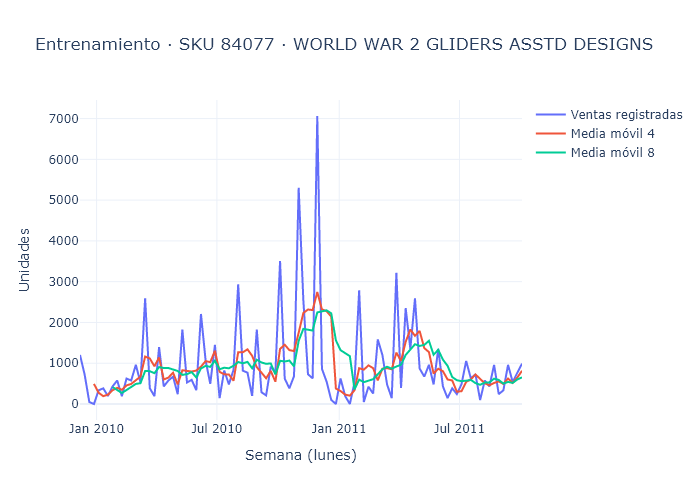

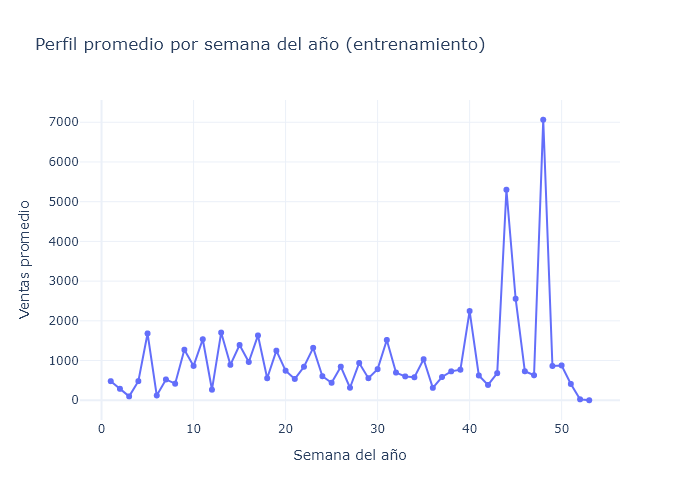

,count,mean,median,max
2009,4,493.0,384.0,1204.0
2010,52,1034.4,608.0,7063.0
2011,40,812.8,558.0,3216.0


Medias por bloques consecutivos de 24 semanas (solo entrenamiento):


,count,mean,median,min,max
1,24,650.42,528.0,0.0,2592.0
2,24,1152.62,769.0,145.0,5301.0
3,24,1169.75,587.0,0.0,7063.0
4,24,705.25,603.5,98.0,2592.0


Autocorrelación exploratoria: lag 1 = 0.022 · lag 4 = 0.378 · lag 52 = -0.128
Cinco semanas de mayor venta en entrenamiento:


,unidades
2010-11-29,7063.0
2010-11-01,5301.0
2010-10-04,3504.0
2011-03-28,3216.0
2010-08-02,2938.0


In [9]:
explora = pd.DataFrame({"ventas": train})
explora["media_movil_4"] = explora["ventas"].rolling(4).mean()
explora["media_movil_8"] = explora["ventas"].rolling(8).mean()
fig = go.Figure()
for col, nombre in [("ventas", "Ventas registradas"), ("media_movil_4", "Media móvil 4"), ("media_movil_8", "Media móvil 8")]:
    fig.add_trace(go.Scatter(x=explora.index, y=explora[col], name=nombre))
fig.update_layout(title=f"Entrenamiento · SKU {SKU} · {desc}", xaxis_title="Semana (lunes)", yaxis_title="Unidades")
fig.show()

perfil = (explora.assign(semana_anio=explora.index.isocalendar().week.astype(int))
          .groupby("semana_anio")["ventas"].mean().reset_index())
fig = px.line(perfil, x="semana_anio", y="ventas", markers=True,
              title="Perfil promedio por semana del año (entrenamiento)",
              labels={"semana_anio": "Semana del año", "ventas": "Ventas promedio"})
fig.show()

anual = train.groupby(train.index.year).agg(["count", "mean", "median", "max"])
display(anual.round(1))
print("Medias por bloques consecutivos de 24 semanas (solo entrenamiento):")
display(train.groupby(np.arange(len(train)) // 24 + 1).agg(["count", "mean", "median", "min", "max"]).round(2))
print("Autocorrelación exploratoria: lag 1 =", round(train.autocorr(1), 3),
      "· lag 4 =", round(train.autocorr(4), 3), "· lag 52 =", round(train.autocorr(52), 3))
print("Cinco semanas de mayor venta en entrenamiento:")
display(train.nlargest(5).to_frame())


**Lectura de la salida:**

Los gráficos y las medias por bloques muestran aumento intermedio y descenso posterior, con picos en 2010. La autocorrelación a cuatro semanas es 0,378; a 52 semanas es −0,128 con poca historia anual. Estas evidencias orientan hipótesis; no certifican estacionalidad ni un quiebre persistente.

### Pregunta 3
Identifique evidencia de tendencia, estacionalidad o quiebres en el entrenamiento. Diferencie lo que observa de lo que todavía necesita comprobar, y explique qué representa un cero en la serie.

**Respuesta:**

No observo una tendencia ascendente sostenida: las medias de los cuatro bloques de 24 semanas son **650,42 → 1.152,62 → 1.169,75 → 705,25** unidades. La media global (919,51) supera bastante a la mediana (584,50), coherente con picos que elevan el promedio. Destacan 7.063 unidades el 29/11/2010 y 5.301 el 01/11/2010. Las medias anuales de 2009 y 2011 corresponden a solo cuatro y 40 semanas de entrenamiento, respectivamente; no son años completos comparables.

La autocorrelación exploratoria a cuatro semanas es **0,378** y a 52 semanas **−0,128**. El primer valor sugiere una asociación que merece contrastarse, pero no demuestra que el negocio tenga un ciclo fijo de cuatro semanas. Con 96 semanas ni siquiera se observan dos ciclos anuales completos. Tampoco basta un pico aislado para afirmar un quiebre: haría falta un cambio persistente y contexto comercial.

Los tres ceros son 28/12/2009, 27/12/2010 y 17/01/2011. En las dos primeras no hay registros UK válidos de ningún producto; en la última sí los hay de la tienda, pero no del SKU. **Cero significa ausencia de ventas registradas bajo estos filtros**. No confirma demanda nula, existencia de inventario ni cierre de la tienda.

# 8. Modelos, cantidad operativa, costo y regla de selección

- **Naïve:** repite la última semana observada.
- **Naïve estacional (m = 4):** repite la semana de hace 4 semanas. El periodo de 4 semanas es un **supuesto de modelado** (ciclo operativo corto), no una propiedad comprobada del negocio; con 96 semanas de entrenamiento no hay suficientes años para estimar con confianza un ciclo anual de 52 semanas.
- **Exponential Smoothing:** nivel y tendencia aditivos con estacionalidad aditiva m = 4. Si un entrenamiento tuviera menos de 2 × 4 + 8 = 16 semanas, se simplifica a nivel y tendencia (documentado; se informa si ocurre).

**Cantidad operativa:** todo pronóstico se convierte en `max(redondeo(pronóstico), 0)` y **todas** las métricas y costos se calculan sobre esa cantidad.

**Costo base (supuesto académico, no proviene de UCI):** £0,40 por unidad excedente y £1,50 por unidad faltante.

**Regla única de selección** (se usa para el modelo, la política de colchón, el Reto 1 y el Reto 3):
1. Candidatos: costo promedio de validación ≤ mínimo × 1,01 (**incluye** exactamente el 1 %; se admite una holgura de 1e-9 por redondeo numérico). Si el mínimo es 0, solo son candidatos los costos iguales a 0.
2. Desempate entre candidatos: menor MAE promedio, luego menor desviación del costo y, al final, menor complejidad.

In [10]:
SEASON = 4
OVER_COST, SHORT_COST = 0.40, 1.50
MODELOS = ["Naive", "SeasonalNaive", "ExpSmoothing"]   # en orden de complejidad
TOLERANCIA = 0.01
registro_ajustes = []

def ajustar_es(y, etiqueta):
    """Ajusta Exponential Smoothing y registra todas las advertencias del ajuste."""
    if len(y) >= 2 * SEASON + 8:
        modelo = ExponentialSmoothing(y, trend="add", seasonal="add", seasonal_periods=SEASON,
                                      initialization_method="estimated")
        especificacion = "nivel + tendencia + estacionalidad aditivas (m = 4)"
    else:
        modelo = ExponentialSmoothing(y, trend="add", seasonal=None, initialization_method="estimated")
        especificacion = "simplificado: nivel + tendencia"
    with warnings.catch_warnings(record=True) as avisos:
        warnings.simplefilter("always")
        ajuste = modelo.fit(optimized=True)
    registro_ajustes.append({"etapa": etiqueta.split(" · ")[0], "ajuste": etiqueta, "n_train": len(y),
                             "especificacion": especificacion, "advertencias": len(avisos),
                             "tipos": "; ".join(sorted({w.category.__name__ for w in avisos})),
                             "mensajes": " | ".join(sorted({str(w.message)[:110] for w in avisos}))})
    return ajuste

def pronosticar(modelo, y, h, etiqueta=""):
    if modelo == "Naive":
        f = np.repeat(y.iloc[-1], h)
    elif modelo == "SeasonalNaive":
        f = np.resize(y.iloc[-SEASON:].values, h)
    elif modelo == "ExpSmoothing":
        f = np.asarray(ajustar_es(y, etiqueta).forecast(h), dtype=float)
    else:
        raise ValueError(modelo)
    return np.maximum(np.round(f), 0)   # cantidad operativa

def evaluar(real, cantidad, over=OVER_COST, short=SHORT_COST):
    real, cantidad = np.asarray(real, float), np.asarray(cantidad, float)
    exceso, faltante = np.maximum(cantidad - real, 0), np.maximum(real - cantidad, 0)
    return {"MAE": mean_absolute_error(real, cantidad),
            "RMSE": mean_squared_error(real, cantidad) ** 0.5,
            "WAPE": np.abs(real - cantidad).sum() / real.sum() if real.sum() > 0 else np.nan,  # no definido si la demanda total es 0
            "unidades_excedentes": exceso.sum(), "unidades_faltantes": faltante.sum(),
            "costo": (exceso * over + faltante * short).sum()}

def resumir(filas, por, orden):
    """Resume los folds por modelo o por política. 'orden' va de la opción más simple a la más compleja."""
    t = (pd.DataFrame(filas).groupby(por)
           .agg(costo_prom=("costo", "mean"), costo_sd=("costo", "std"),
                MAE_prom=("MAE", "mean"), MAE_sd=("MAE", "std"), RMSE_prom=("RMSE", "mean"),
                WAPE_prom=("WAPE", "mean"), excedentes=("unidades_excedentes", "sum"),
                faltantes=("unidades_faltantes", "sum"))
           .reindex(orden))
    t["complejidad"] = range(len(orden))
    return t

def seleccionar(tabla, tol=TOLERANCIA):
    """Regla única de selección (ver el texto de esta sección)."""
    minimo = tabla["costo_prom"].min()
    limite = minimo * (1 + tol)          # si minimo == 0, limite == 0: solo empatan costos 0
    candidatos = tabla[tabla["costo_prom"] <= limite + 1e-9]
    return candidatos.sort_values(["MAE_prom", "costo_sd", "complejidad"], kind="stable").index[0]
print("Funciones listas.")

Funciones listas.


**Lectura de la salida:**

Quedan definidos los tres modelos y una transformación común a enteros no negativos. El faltante cuesta **3,75 veces** el excedente. La tolerancia del 1 % admite candidatos cercanos en costo y el desempate prioriza MAE, desviación de costo y complejidad; estas reglas se fijan antes de comparar resultados.

# 9. Backtesting rolling-origin (solo con el entrenamiento)

Cada fold entrena con todo lo anterior a su origen y pronostica las **8 semanas** siguientes, igual que el test final. Se exige al menos 52 semanas de entrenamiento; los bloques de validación no se superponen y el último termina justo antes del test. La celda **comprueba** que ningún fold invada el test.

In [11]:
BT_H, MIN_TRAIN = 8, 52
origenes = list(range(len(train) - BT_H, MIN_TRAIN - 1, -BT_H))[::-1]

def backtest(y, modelos, etiqueta):
    """Pronostica cada bloque de validación desde su origen. Devuelve métricas por fold y cantidades."""
    filas, cantidades = [], {}
    for k, origen in enumerate(origenes, start=1):
        tr, va = y.iloc[:origen], y.iloc[origen:origen + BT_H]
        assert tr.index[-1] < va.index[0] and va.index[-1] < semanas_test[0], "un fold invade el test"
        for m in modelos:
            cantidades[(k, m)] = pronosticar(m, tr, BT_H, f"{etiqueta} · fold {k}")
            filas.append({**evaluar(va, cantidades[(k, m)]), "fold": k, "modelo": m})
    return filas, cantidades

filas_bt, q_bt = backtest(train, MODELOS, "backtesting")
bt = pd.DataFrame(filas_bt)
folds = pd.DataFrame([{"fold": k, "entrenamiento": f"{train.index[0].date()} → {train.index[o - 1].date()}", "n_train": o,
                       "validacion": f"{train.index[o].date()} → {train.index[o + BT_H - 1].date()}"}
                      for k, o in enumerate(origenes, start=1)])
display(folds)
display(bt.round(2))
print("Comprobado: los", len(origenes), "folds terminan antes del test (", semanas_test[0].date(), ").")

,fold,entrenamiento,n_train,validacion
0,1,2009-12-07 → 2010-12-27,56,2011-01-03 → 2011-02-21
1,2,2009-12-07 → 2011-02-21,64,2011-02-28 → 2011-04-18
2,3,2009-12-07 → 2011-04-18,72,2011-04-25 → 2011-06-13
3,4,2009-12-07 → 2011-06-13,80,2011-06-20 → 2011-08-08
4,5,2009-12-07 → 2011-08-08,88,2011-08-15 → 2011-10-03


,MAE,RMSE,WAPE,unidades_excedentes,unidades_faltantes,costo,fold,modelo
0,608.12,1044.62,1.00,0.0,4865.0,7297.5,1,Naive
1,528.88,758.45,0.87,1195.0,3036.0,5032.0,1,SeasonalNaive
2,1599.12,1838.12,2.63,11475.0,1318.0,6567.0,1,ExpSmoothing
3,1111.12,1460.84,0.83,113.0,8776.0,13209.2,2,Naive
4,789.88,1000.51,0.59,1317.0,5002.0,8029.8,2,SeasonalNaive
5,949.12,1147.68,0.71,4251.0,3342.0,6713.4,2,ExpSmoothing
6,723.88,824.92,0.77,4550.0,1241.0,3681.5,3,Naive
7,1248.88,1463.50,1.33,8557.0,1434.0,5573.8,3,SeasonalNaive
8,850.75,960.03,0.91,5384.0,1422.0,4286.6,3,ExpSmoothing
9,391.88,471.10,0.75,47.0,3088.0,4650.8,4,Naive


Comprobado: los 5 folds terminan antes del test ( 2011-10-10 ).


**Lectura de la salida:**

Los cinco folds entrenan con **56, 64, 72, 80 y 88 semanas**, pronostican ocho y cubren validación del 03/01 al 03/10/2011. No se superponen y ninguno alcanza el test del 10/10. El fold 1 de Naïve pronostica cero porque su última observación es la semana sin registros del 27/12/2010: muestra un riesgo concreto de los ceros imputados.

,costo_prom,costo_sd,MAE_prom,MAE_sd,RMSE_prom,WAPE_prom,excedentes,faltantes,complejidad
modelo,,,,,,,,,
Naive,6239.22,4296.41,620.20,327.68,819.13,0.75,5469.0,19339.0,0
SeasonalNaive,4950.34,2065.83,666.50,370.02,830.61,0.83,13853.0,12807.0,1
ExpSmoothing,4312.56,2352.88,898.32,465.13,1030.27,1.24,29397.0,6536.0,2


MODELO SELECCIONADO EN VALIDACIÓN (fijado antes de mirar el test): ExpSmoothing


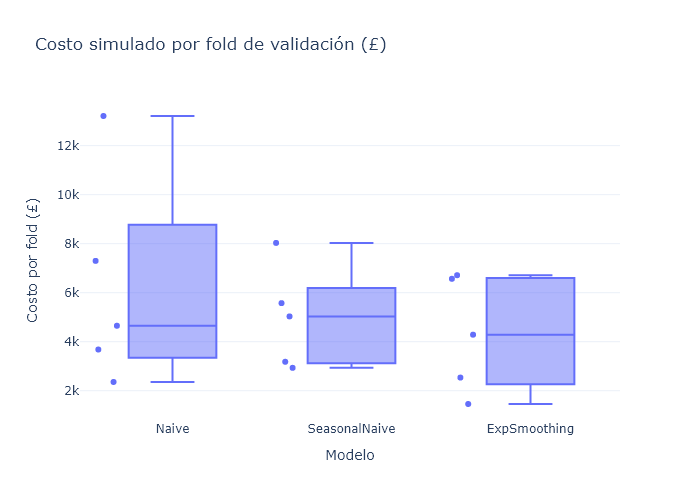

In [12]:
resumen_val = resumir(filas_bt, "modelo", MODELOS)
SELECCIONADO = seleccionar(resumen_val)
display(resumen_val.round(2))
print("MODELO SELECCIONADO EN VALIDACIÓN (fijado antes de mirar el test):", SELECCIONADO)
fig = px.box(bt, x="modelo", y="costo", points="all", title="Costo simulado por fold de validación (£)",
             labels={"modelo": "Modelo", "costo": "Costo por fold (£)"})
fig.show()

**Lectura de la salida:**

Exponential Smoothing minimiza el costo medio (**£4.312,56**), aunque Naïve tiene menor MAE y RMSE medios. Con 29.397 excedentes y 6.536 faltantes, Exponential Smoothing desplaza el error hacia el lado de menor costo. La desviación de costo (£2.352,88) y el diagrama por fold revelan variabilidad relevante.

### Pregunta 4
¿Qué modelo se seleccionó en validación y con qué regla? ¿Coinciden el ranking por costo y el ranking por MAE o RMSE? ¿Por qué el ranking por WAPE no aporta un criterio adicional al MAE?

**Respuesta:**

Se seleccionó **Exponential Smoothing**: costo medio £4.312,56 frente a £4.950,34 de SeasonalNaive y £6.239,22 de Naïve. El límite de candidatos es **£4.312,56 × 1,01 = £4.355,69**; solo entra Exponential Smoothing. Por tanto no fue necesario desempatar por MAE, desviación del costo o complejidad.

Los rankings se invierten: por costo, Exponential Smoothing → SeasonalNaive → Naïve; por MAE medio, Naïve (620,20) → SeasonalNaive (666,50) → Exponential Smoothing (898,32). Por RMSE medio se mantiene ese orden: 819,13; 830,61 y 1.030,27. Exponential Smoothing acumula más excedentes (29.397), pero reduce faltantes a 6.536 frente a 19.339 de Naïve: con el faltante a £1,50, esa dirección del error abarata la validación.

En **un mismo fold**, WAPE = MAE × 8 / ventas de ese fold, con denominador común para todos los modelos; no añade un criterio independiente al MAE. La tabla promedia los WAPE de los cinco folds: ese promedio pondera implícitamente más los periodos con menor venta y no equivale al WAPE global de las 40 semanas. En esta ejecución también ordena Naïve → SeasonalNaive → Exponential Smoothing, pero la equivalencia exacta con MAE se refiere al mismo conjunto de semanas, no a cualquier promedio de ratios.

### Pregunta 5
¿Qué tan estable fue cada modelo entre folds? Use la desviación del costo y del MAE.

**Respuesta:**

La estabilidad depende de la medida. **Naïve** tiene la mayor desviación de costo (£4.296,41), con costos entre £2.357,10 y £13.209,20; su desviación de MAE es 327,68 unidades. **SeasonalNaive** presenta la menor desviación de costo (£2.065,83), con desviación de MAE 370,02. **Exponential Smoothing** tiene desviación de costo £2.352,88 y la mayor desviación de MAE: 465,13.

Exponential Smoothing mejora el costo de Naïve en **cuatro de cinco folds**, pero en el tercero cuesta £4.286,60 frente a £3.681,50: pierde £605,10. Sus costos varían de £1.458,60 a £6.713,40. Fue la opción más barata en promedio, pero no una solución uniformemente estable; SeasonalNaive fue más estable por desviación del costo. Las desviaciones son descriptivas de cinco folds, no intervalos de confianza ni garantías futuras.

# 10. Política de colchón calibrada sin información futura (antes del test)

El colchón suma unidades al pronóstico para protegerse de faltantes: **colchón = ⌈multiplicador × MAE previo⌉**. Se comparan los multiplicadores 0; 0,5; 1 y 1,5.

**Regla de calibración (sin errores futuros).** Para cada origen, el *MAE previo* se calcula con el modelo seleccionado en los **2 bloques de 8 semanas inmediatamente anteriores** a ese origen: cada bloque se pronostica entrenando solo con lo anterior a él. Así, el colchón del fold 1 usa solo errores anteriores al fold 1.
- Si no hay historia suficiente (algún bloque quedaría con menos de 16 semanas de entrenamiento), el colchón de ese origen es **0** y se informa. Con 52 semanas mínimas no ocurre en este laboratorio.
- La política (modelo, multiplicador y regla) se elige con la **regla única de selección** y queda **fijada antes del test**.
- Para el test, el MAE previo se calcula con la misma regla desde el final del entrenamiento (solo información previa al test).
- Después de evaluar, la **magnitud** del colchón se actualiza con la historia completa para proyectar, **sin cambiar la regla**.

In [13]:
MULTIPLICADORES = [0, 0.5, 1.0, 1.5]
BLOQUES_CAL = 2

def mae_previo(modelo, y, etiqueta, bloques=BLOQUES_CAL):
    """MAE del modelo en los 'bloques' bloques de 8 semanas que terminan al final de y.
    Solo usa y (información hasta el origen). Devuelve None si la historia no alcanza."""
    errores = []
    for b in range(bloques, 0, -1):
        corte = len(y) - b * BT_H
        if corte < 2 * SEASON + 8:
            return None
        real = y.iloc[corte:corte + BT_H].values
        errores.append(np.abs(real - pronosticar(modelo, y.iloc[:corte], BT_H, f"{etiqueta} · bloque {b}")))
    return float(np.mean(np.concatenate(errores)))

def colchon(mult, mae):
    return 0 if (mae is None or mult == 0) else int(np.ceil(mult * mae))

def comparar_politicas(bloques=BLOQUES_CAL, etiqueta="calibración"):
    filas = []
    for k, origen in enumerate(origenes, start=1):
        tr, va = train.iloc[:origen], train.iloc[origen:origen + BT_H]
        mae_k = mae_previo(SELECCIONADO, tr, f"{etiqueta} · fold {k}", bloques)
        for mult in MULTIPLICADORES:
            c = colchon(mult, mae_k)
            filas.append({**evaluar(va, q_bt[(k, SELECCIONADO)] + c), "fold": k, "multiplicador": mult,
                          "mae_previo": mae_k, "colchon": c,
                          "ultima_semana_calibracion": tr.index[-1].date(), "inicio_validacion": va.index[0].date()})
    return pd.DataFrame(filas)

pol_folds = comparar_politicas()
assert (pol_folds["ultima_semana_calibracion"] < pol_folds["inicio_validacion"]).all(), "colchón con información futura"
resumen_pol = resumir(pol_folds, "multiplicador", MULTIPLICADORES)
MULT = seleccionar(resumen_pol)

display(pol_folds.loc[pol_folds["multiplicador"] == 1.0,
                      ["fold", "ultima_semana_calibracion", "inicio_validacion", "mae_previo"]].round(1))
display(resumen_pol.round(2))
MAE_TEST = mae_previo(SELECCIONADO, train, "calibración test")       # solo entrenamiento
COLCHON_TEST = colchon(MULT, MAE_TEST)
POLITICA = f"{SELECCIONADO} + {MULT:g} × MAE previo"
print("POLÍTICA FIJADA ANTES DEL TEST:", POLITICA)
print(f"Colchón para el test: {COLCHON_TEST} unidades por semana (MAE previo = {MAE_TEST:.1f}, calculado solo con el entrenamiento)")

,fold,ultima_semana_calibracion,inicio_validacion,mae_previo
2,1,2010-12-27,2011-01-03,1390.9
6,2,2011-02-21,2011-02-28,1523.4
10,3,2011-04-18,2011-04-25,1274.1
14,4,2011-06-13,2011-06-20,899.9
18,5,2011-08-08,2011-08-15,821.8


,costo_prom,costo_sd,MAE_prom,MAE_sd,RMSE_prom,WAPE_prom,excedentes,faltantes,complejidad
multiplicador,,,,,,,,,
0.0,4312.56,2352.88,898.32,465.13,1030.27,1.24,29397.0,6536.0,0
0.5,4654.26,2025.52,1285.68,543.19,1432.18,1.80,48972.0,2455.0,1
1.0,5672.98,1880.14,1761.88,589.00,1938.93,2.46,70316.0,159.0,2
1.5,7504.40,2221.70,2345.12,694.28,2485.28,3.23,93805.0,0.0,3


POLÍTICA FIJADA ANTES DEL TEST: ExpSmoothing + 0 × MAE previo
Colchón para el test: 0 unidades por semana (MAE previo = 546.3, calculado solo con el entrenamiento)


**Lectura de la salida:**

La política elegida es **k = 0**: £4.312,56 por fold frente a £4.654,26, £5.672,98 y £7.504,40 con colchones positivos. El MAE previo al test es **546,3125** y la regla produce cero unidades adicionales. Todas las fechas finales de calibración son anteriores al origen correspondiente.

### Pregunta 6
¿Qué política de colchón quedó fijada antes del test y por qué? Explique por qué el colchón de cada fold se calcula solo con errores anteriores a su origen.

**Respuesta:**

Quedó fijada **Exponential Smoothing + 0 × MAE previo**, es decir, sin colchón. Los costos promedio para k = 0; 0,5; 1 y 1,5 fueron **£4.312,56; £4.654,26; £5.672,98 y £7.504,40**. Solo k = 0 entra en el límite del 1 % (£4.355,69). No se añade inventario porque el incremento de excedentes cuesta más que la reducción de faltantes en esta validación.

El MAE previo al test es **546,3125** unidades y el colchón es `ceil(0 × 546,3125) = 0`. Cada origen utiliza únicamente errores de los dos bloques anteriores de ocho semanas, producidos por modelos entrenados antes de esos bloques. Por ejemplo, el primer fold empieza el 03/01/2011 y su calibración termina el 27/12/2010. Usar los errores del bloque que se va a pronosticar revelaría ventas futuras y fabricaría una política imposible de aplicar en ese momento.

# 11. Evaluación final en test (una sola vez)

Se reentrena cada modelo con las 96 semanas de entrenamiento y se pronostican las 8 semanas de test. Se evalúan los tres modelos sin colchón y la **política fijada**. Si otra opción resulta mejor aquí, se informa, pero **no** cambia la selección.

,MAE,RMSE,WAPE,unidades_excedentes,unidades_faltantes,costo
opcion,,,,,,
Naive (sin colchón),678.75,1545.12,0.48,961.0,4469.0,7087.9
SeasonalNaive (sin colchón),773.75,1631.81,0.54,641.0,5549.0,8579.9
ExpSmoothing (sin colchón),776.62,1700.86,0.54,329.0,5884.0,8957.6


Política evaluada: ExpSmoothing + 0 × MAE previo
Sobrecosto frente a Naïve: £1869.70 (26.4 %).
Retrospectivamente, «Naive (sin colchón)» habría costado menos en test; la selección no cambia.


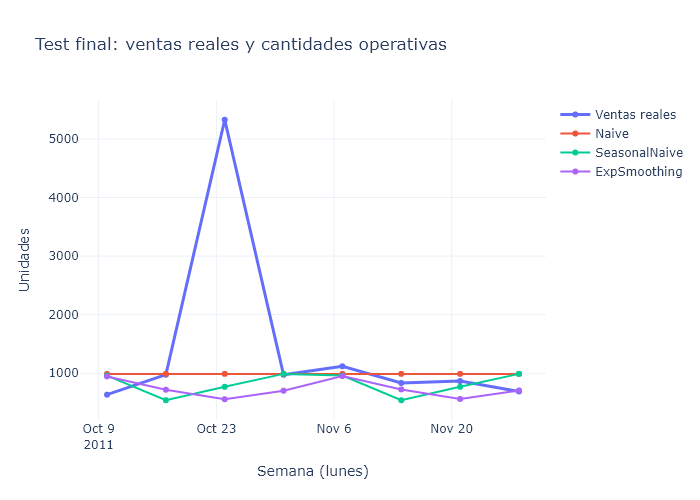

Detalle por semana del test:


,real,Naive,SeasonalNaive,ExpSmoothing,politica_fijada
2011-10-10,634,989,960,946,946
2011-10-17,975,989,539,719,719
2011-10-24,5328,989,768,556,556
2011-10-31,974,989,989,701,701
2011-11-07,1119,989,960,952,952
2011-11-14,834,989,539,724,724
2011-11-21,867,989,768,561,561
2011-11-28,689,989,989,706,706


In [14]:
cantidades_test = {m: pronosticar(m, train, TEST_H, "test") for m in MODELOS}
q_politica = cantidades_test[SELECCIONADO] + COLCHON_TEST
filas = [{**evaluar(test, q), "opcion": f"{m} (sin colchón)"} for m, q in cantidades_test.items()]
if MULT > 0:
    filas.append({**evaluar(test, q_politica), "opcion": f"Política fijada: {POLITICA}"})
res_test = pd.DataFrame(filas).set_index("opcion")
display(res_test.round(2))

fila_pol = f"Política fijada: {POLITICA}" if MULT > 0 else f"{SELECCIONADO} (sin colchón)"
costo_pol, costo_naive = res_test.loc[fila_pol, "costo"], res_test.loc["Naive (sin colchón)", "costo"]
diferencia = costo_naive - costo_pol        # > 0 ahorro; < 0 sobrecosto
print("Política evaluada:", POLITICA)
if SELECCIONADO == "Naive" and MULT == 0:
    print("La política seleccionada es el propio Naïve: no hay diferencia que calcular frente a él.")
elif costo_naive == 0:
    print(f"Diferencia frente a Naïve: £{diferencia:.2f}. No se calcula porcentaje porque el costo de Naïve es cero.")
elif diferencia > 0:
    print(f"Ahorro frente a Naïve: £{diferencia:.2f} ({diferencia / costo_naive * 100:.1f} %).")
else:
    print(f"Sobrecosto frente a Naïve: £{-diferencia:.2f} ({-diferencia / costo_naive * 100:.1f} %).")
mejor_retro = res_test["costo"].idxmin()
if mejor_retro != fila_pol:
    print(f"Retrospectivamente, «{mejor_retro}» habría costado menos en test; la selección no cambia.")

fig = go.Figure()
fig.add_trace(go.Scatter(x=test.index, y=test.values, mode="lines+markers", name="Ventas reales", line=dict(width=3)))
for m, q in cantidades_test.items():
    fig.add_trace(go.Scatter(x=test.index, y=q, mode="lines+markers", name=m))
fig.update_layout(title="Test final: ventas reales y cantidades operativas", xaxis_title="Semana (lunes)", yaxis_title="Unidades")
fig.show()
detalle_test = pd.DataFrame({"real": test, **cantidades_test, "politica_fijada": q_politica})
print("Detalle por semana del test:")
display(detalle_test.astype(int))


**Lectura de la salida:**

El test conserva la política fijada y muestra **£8.957,60 frente a £7.087,90 de Naïve**. El sobrecosto es £1.869,70 (26,38 %). La semana del 24/10/2011 tiene 5.328 ventas frente a 556 estimadas por Exponential Smoothing; aun así se conserva en la evaluación final.

### Pregunta 7
¿La política seleccionada cumplió en test? Compare su costo con los baselines e indique el ahorro o sobrecosto frente a Naïve. ¿El modelo con menor RMSE fue también el de menor costo?

**Respuesta:**

**No cumplió el criterio económico frente al baseline.** La política fijada costó **£8.957,60**, frente a **£7.087,90 de Naïve** y £8.579,90 de SeasonalNaive. El ahorro firmado es −£1.869,70: se informa como **sobrecosto de £1.869,70 (26,38 %)** frente a Naïve. También cuesta £377,70 más que el baseline estacional.

En este test sí coinciden menor RMSE y menor costo: ambos corresponden a **Naïve**, con RMSE 1.545,12 y costo £7.087,90. SeasonalNaive tiene RMSE 1.631,81 y Exponential Smoothing 1.700,86. La conclusión no modifica la selección hecha con validación: el modelo elegido sigue identificado como Exponential Smoothing, pero **no se adopta como sustituto de Naïve**.

### Diagnóstico del pico del test (retrospectivo)

Se identifica la semana de mayor venta del test y el pedido más grande de esa semana. Un pedido extraordinario **aislado** es un **pico puntual**; un **quiebre estructural** exige un cambio persistente de nivel o patrón, que 8 semanas no permiten confirmar. Los modelos usados son **univariantes**: solo ven las ventas pasadas del SKU y no disponían de información específica sobre ese pedido.

La evaluación principal **conserva** esa semana. El cálculo sin ella es un **análisis retrospectivo de sensibilidad**, no una evaluación alternativa.

In [15]:
semana_pico = test.idxmax()
lineas_pico = uk[(uk["StockCode"] == SKU) & (uk["week"] == semana_pico)]
pedidos = lineas_pico.groupby(["InvoiceNo", "CustomerID"], dropna=False)["Quantity"].sum().sort_values(ascending=False)
print(f"Semana de mayor venta en test: {semana_pico.date()} · {test.max():.0f} unidades")
factura, cliente = pedidos.index[0]
cliente = "sin dato" if pd.isna(cliente) else str(cliente).removesuffix(".0")
print(f"Pedido más grande: factura {factura} · cliente {cliente} · {pedidos.iloc[0]:.0f} unidades "
      f"({pedidos.iloc[0] / test.max() * 100:.1f} % de la semana)")
print("Mediana semanal del entrenamiento:", train.median(), "unidades")

sin_pico = test.index != semana_pico
sens = pd.DataFrame({m: evaluar(test[sin_pico], cantidades_test[m][sin_pico]) for m in MODELOS}).T
if MULT > 0:
    sens.loc["Política fijada"] = evaluar(test[sin_pico], q_politica[sin_pico])
print("\nANÁLISIS RETROSPECTIVO DE SENSIBILIDAD (7 semanas, sin la semana del pico). No reemplaza la evaluación principal.")
display(sens[["MAE", "unidades_excedentes", "unidades_faltantes", "costo"]].round(2))

Semana de mayor venta en test: 2011-10-24 · 5328 unidades
Pedido más grande: factura 573008 · cliente 12901 · 4800 unidades (90.1 % de la semana)
Mediana semanal del entrenamiento: 584.5 unidades

ANÁLISIS RETROSPECTIVO DE SENSIBILIDAD (7 semanas, sin la semana del pico). No reemplaza la evaluación principal.


,MAE,unidades_excedentes,unidades_faltantes,costo
Naive,155.86,961.0,130.0,579.4
SeasonalNaive,232.86,641.0,989.0,1739.9
ExpSmoothing,205.86,329.0,1112.0,1799.6


**Lectura de la salida:**

El pedido de **4.800 unidades** concentra el **90,09 %** de las ventas de la semana pico. Retirarla solo para diagnóstico reduce el costo de Exponential Smoothing a £1.799,60, pero Naïve sigue costando menos (£579,40). El modelo falla también fuera del pico; la evaluación principal sigue siendo de ocho semanas.

### Pregunta 8
¿Qué error fue más grave en el test: sobreestimar o subestimar? Use las unidades y los costos. ¿El pico del test indica un quiebre estructural o un pico puntual? ¿Qué muestra, y qué no, el análisis de sensibilidad sin esa semana?

**Respuesta:**

El problema dominante es **subestimar**. Exponential Smoothing deja **5.884 unidades faltantes × £1,50 = £8.826,00**, frente a **329 excedentes × £0,40 = £131,60**; los faltantes explican el 98,53 % de su costo total (£8.957,60). Naïve deja 4.469 faltantes (£6.703,50) y 961 excedentes (£384,40).

La semana del **24/10/2011** suma 5.328 unidades; la factura **573008**, cliente **12901**, aporta 4.800 (90,09 %). Es un pico asociado a un pedido concreto, y las semanas siguientes vuelven a 974, 1.119, 834, 867 y 689 unidades. Esta evidencia favorece la interpretación de **pico puntual**, sin demostrar causalidad ni descartar cualquier cambio futuro; un quiebre estructural requiere persistencia.

Sin esa semana, Exponential Smoothing aún cuesta **£1.799,60 frente a £579,40 de Naïve**, un sobrecosto de £1.220,20. Por tanto el pedido extraordinario agrava el resultado, pero no explica toda la desventaja. El análisis retrospectivo de siete semanas muestra sensibilidad a la concentración del error; no autoriza borrar el pico, sustituir el test principal ni elegir otro modelo con esos datos.

# 12. Reentrenamiento final y proyección académica

Después de cerrar la evaluación se reentrena el modelo seleccionado con **toda** la historia (104 semanas) y se actualiza la **magnitud** del colchón con la misma regla (los 2 bloques más recientes, que ahora incluyen el test). Se muestra también la proyección de Naïve como referencia.

La tabla es una **proyección académica**, no una orden de compra:
- La **cantidad objetivo semanal** es un objetivo para cada semana. El laboratorio **no simula el arrastre de inventario** entre semanas: si una semana sobra mercadería, esta reduce la necesidad de la siguiente. Por eso la suma de los objetivos semanales no equivale a la cantidad a comprar.
- Una compra simplificada para una semana sería `max(objetivo − inventario utilizable − pedidos que llegarán a tiempo, 0)`: nunca negativa, y solo cuenta el inventario apto para la venta y los pedidos que llegarán antes de esa semana. El laboratorio no dispone de esos datos.

In [16]:
FINAL_H = 8
pron_final = pronosticar(SELECCIONADO, serie, FINAL_H, "final")
pron_naive = pronosticar("Naive", serie, FINAL_H, "final")
MAE_FINAL = mae_previo(SELECCIONADO, serie, "calibración final")   # misma regla, historia completa
COLCHON_FINAL = colchon(MULT, MAE_FINAL)
semanas_futuras = pd.date_range(serie.index[-1] + pd.Timedelta(weeks=1), periods=FINAL_H, freq="W-MON")
plan = pd.DataFrame({"Semana": semanas_futuras.date,
                     f"Pronóstico {SELECCIONADO}": pron_final.astype(int),
                     "Colchón (política fijada)": COLCHON_FINAL,
                     "Cantidad objetivo semanal": (pron_final + COLCHON_FINAL).astype(int),
                     "Referencia Naïve": pron_naive.astype(int)})
display(plan)
print(f"Política aplicada: {POLITICA} · MAE previo actualizado = {MAE_FINAL:.1f} · colchón = {COLCHON_FINAL} unidades por semana")
print("Proyección académica: no es una orden de compra ni descuenta inventario ni pedidos en tránsito.")

C:\Users\ASUS\AppData\Local\Temp\ipykernel_26888\3259582610.py:6: DeprecationWarning:

The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`).Please use a specific unit instead.



,Semana,Pronóstico ExpSmoothing,Colchón (política fijada),Cantidad objetivo semanal,Referencia Naïve
0,2011-12-05,1075,0,1075,689
1,2011-12-12,899,0,899,689
2,2011-12-19,1617,0,1617,689
3,2011-12-26,998,0,998,689
4,2012-01-02,1103,0,1103,689
5,2012-01-09,927,0,927,689
6,2012-01-16,1645,0,1645,689
7,2012-01-23,1027,0,1027,689


Política aplicada: ExpSmoothing + 0 × MAE previo · MAE previo actualizado = 538.2 · colchón = 0 unidades por semana
Proyección académica: no es una orden de compra ni descuenta inventario ni pedidos en tránsito.


**Lectura de la salida:**

Tras cerrar la evaluación se reentrena con las 104 semanas y el MAE previo pasa a **538,1875**; k sigue en cero. Los objetivos históricos del **05/12/2011 al 23/01/2012** son 1.075, 899, 1.617, 998, 1.103, 927, 1.645 y 1.027: suman **9.291**. Es una proyección desde el corte histórico, no un pronóstico para 2026 ni una compra aprobada; tampoco revoca la decisión de no adoptar.

# 13. Decisión de adopción y resumen automático

La decisión se toma con una regla fijada de antemano:
- **Adoptar** (como piloto controlado): la política seleccionada costó menos que Naïve en el test **y** en la mayoría de los folds de validación.
- **Mantener en evaluación:** superó a Naïve en el test, pero no de forma consistente en validación.
- **No adoptar como sustituto de Naïve:** en el test costó igual o más que Naïve. Naïve sigue como referencia; el modelo puede seguir evaluándose sin decidir compras con él.

Un **piloto** sirve para comprobar, durante varias semanas nuevas y con la misma regla, si la política reduce el costo frente a Naïve; no justifica por sí mismo una cantidad de compra.

In [17]:
naive_bt = bt[bt["modelo"] == "Naive"].set_index("fold")["costo"]
pol_bt = pol_folds[pol_folds["multiplicador"] == MULT].set_index("fold")["costo"]
folds_ganados = int((pol_bt < naive_bt).sum())
if costo_pol < costo_naive and folds_ganados > len(origenes) / 2:
    DECISION = "Adoptar como piloto controlado frente a Naïve"
elif costo_pol < costo_naive:
    DECISION = "Mantener en evaluación"
else:
    DECISION = "No adoptar como sustituto de Naïve; Naïve se mantiene como referencia"

resumen = {
    "Producto analizado": f"{SKU} · {desc}",
    "Seleccionado antes del test": f"{SELECCIONADO}; política {POLITICA} (regla única de selección)",
    "Costo promedio de validación de la política": f"£{resumen_pol.loc[MULT, 'costo_prom']:.2f} ± £{resumen_pol.loc[MULT, 'costo_sd']:.2f} ({len(origenes)} folds)",
    "Folds de validación en que superó a Naïve": f"{folds_ganados} de {len(origenes)}",
    "Resultado en test (8 semanas)": f"£{costo_pol:.2f} frente a £{costo_naive:.2f} de Naïve",
    "Frente a Naïve": ("ahorro" if diferencia > 0 else "sobrecosto") + f" de £{abs(diferencia):.2f}" + (f" ({abs(diferencia) / costo_naive * 100:.1f} %)" if costo_naive > 0 else ""),
    "Unidades excedentes / faltantes en test": f"{res_test.loc[fila_pol, 'unidades_excedentes']:.0f} / {res_test.loc[fila_pol, 'unidades_faltantes']:.0f}",
    "Decisión": DECISION,
    "Proyección académica (suma de objetivos semanales)": f"{int(plan['Cantidad objetivo semanal'].sum())} unidades; no es una orden de compra",
}
for k, v in resumen.items():
    print(f"{k}: {v}")

Producto analizado: 84077 · WORLD WAR 2 GLIDERS ASSTD DESIGNS
Seleccionado antes del test: ExpSmoothing; política ExpSmoothing + 0 × MAE previo (regla única de selección)
Costo promedio de validación de la política: £4312.56 ± £2352.88 (5 folds)
Folds de validación en que superó a Naïve: 4 de 5
Resultado en test (8 semanas): £8957.60 frente a £7087.90 de Naïve
Frente a Naïve: sobrecosto de £1869.70 (26.4 %)
Unidades excedentes / faltantes en test: 329 / 5884
Decisión: No adoptar como sustituto de Naïve; Naïve se mantiene como referencia
Proyección académica (suma de objetivos semanales): 9291 unidades; no es una orden de compra


**Lectura de la salida:**

La regla da **no adoptar como sustituto de Naïve**: ganar cuatro de cinco folds no compensa perder en test. El costo excede al baseline £1.869,70. La proyección se mantiene únicamente para completar el ejercicio académico y queda separada de una recomendación de abastecimiento.

### Pregunta 9 — Cierre ejecutivo
Cierre ejecutivo (máximo 12 líneas). Distinga: modelo y política seleccionados antes del test; resultado de su evaluación frente a Naïve; decisión (adoptar, mantener en evaluación o no adoptar) y su fundamento; proyección académica y por qué no es una orden de compra; una condición que cambiaría la decisión; y las limitaciones (supuestos de costos, ceros, disponibilidad y un solo test de 8 semanas).

**Respuesta:**

Modelo elegido antes del test: Exponential Smoothing aditivo, m = 4.  
Política fijada: k = 0; costo medio de validación £4.312,56, desviación £2.352,88.  
Mejoró el costo de Naïve en cuatro de cinco folds.  
En test costó £8.957,60 frente a £7.087,90: sobrecosto £1.869,70 (26,38 %).  
Decisión: no adoptar como sustituto de Naïve; la ventaja de validación no se sostuvo fuera de muestra.  
Los 5.884 faltantes explican £8.826,00 del costo; el pedido extraordinario concentra parte del riesgo.  
La proyección histórica suma 9.291 objetivos semanales y mantiene k = 0.  
No es compra: faltan inventario utilizable, llegadas a tiempo y arrastre entre semanas.  
Reabriría la decisión tras nuevos bloques prospectivos con ahorro frente a Naïve y estabilidad suficiente.  
Límites: costos académicos, ceros ambiguos, disponibilidad desconocida y un solo test de ocho semanas.

# 14. Retos individuales de aplicación

La parte guiada ya desarrolló los procedimientos. En esta sección los aplicará a tres casos empresariales. Cada reto tiene cuatro apartados: **A** plantear o preparar el análisis, **B** implementar y obtener resultados, **C** comparar e interpretar la evidencia y **D** formular una decisión justificada con sus limitaciones. Reutilice las funciones de la parte guiada (`evaluar`, `resumir`, `seleccionar`, `backtest`, `pronosticar`, `mae_previo`, `colchon` y `comparar_politicas`) y los objetos ya calculados (`train`, `test`, `origenes`, `q_bt`, `cantidades_test`, `elegibles`). No modifique datos, semanas, pronósticos ni el test. Las respuestas deben ser breves, pero suficientes para justificar la decisión con cifras.

> **Entrega.** «Resuelva los tres retos y sus apartados A, B, C y D en su notebook personal. Guarde la versión ejecutada, con resultados e interpretaciones, en la carpeta semana10/ de su repositorio personal de GitHub y en su propio Google Colab. En la actividad de la semana, en el espacio habilitado, presente ambos enlaces: GitHub y Colab. Verifique que permitan la revisión del trabajo.»

## Reto 1 — Una campaña cambia el costo de los faltantes

**Caso.** La empresa prepara una campaña comercial. Durante la campaña, quedarse sin producto significa perder ventas y clientes que llegaron por la promoción, mientras que guardar unidades sobrantes cuesta menos. El responsable de abastecimiento necesita saber si la recomendación del modelo cambia cuando el faltante se vuelve más costoso.

**Problema.** ¿Se elegiría el mismo método de pronóstico bajo distintos costos del error y, con la evidencia del test, cuál debería usar abastecimiento como referencia?

**Datos, supuestos y recursos**
- Producto y semanas del laboratorio; pronósticos de validación ya calculados (`q_bt`) y cantidades de test (`cantidades_test`).
- Escenarios de costo (supuestos académicos, no provienen de UCI): A faltante £1,00 y exceso £0,50; B faltante £1,50 y exceso £0,40 (base); C faltante £3,00 y exceso £0,25.
- Regla común de selección (`resumir` y `seleccionar`). No se modifican ventas ni pronósticos para favorecer un resultado.

**Apartados**
- **A.** Plantear los escenarios y la decisión
- **B.** Calcular los costos de validación y seleccionar
- **C.** Evaluar en test y comparar frente a Naïve
- **D.** Recomendar a abastecimiento

**Evidencias que deben quedar en el notebook**
- Tabla de escenarios con la razón faltante / exceso.
- Tabla de costos promedio de validación por escenario y modelo, con el seleccionado.
- Tabla de test con excedentes, faltantes, costo y diferencia frente a Naïve, y su gráfico.
- Interpretaciones A–D.

### Reto 1 · Apartado A — Plantear los escenarios y la decisión
Construya una tabla con los tres escenarios y la razón faltante / exceso. Explique qué representa cada escenario para el negocio y formule la decisión empresarial que se tomará con el análisis.

In [18]:
ESCENARIOS = {"A": (1.00, 0.50), "B": (1.50, 0.40), "C": (3.00, 0.25)}
r1_escenarios = pd.DataFrame([
    {"escenario": esc, "faltante": short, "exceso": over,
     "faltante / exceso": short / over, "cuantil_critico": short / (short + over)}
    for esc, (short, over) in ESCENARIOS.items()
]).set_index("escenario")
display(r1_escenarios.round(4))

,faltante,exceso,faltante / exceso,cuantil_critico
escenario,,,,
A,1.0,0.50,2.00,0.6667
B,1.5,0.40,3.75,0.7895
C,3.0,0.25,12.00,0.9231


**Lectura de la salida:**

La razón faltante/excedente aumenta **2 → 3,75 → 12**. Los escenarios alteran la valoración de las mismas cantidades, permitiendo medir sensibilidad de la elección sin cambiar datos ni aprovechar el test.

**Interpretación 1A:**

A supone que faltar cuesta dos veces exceder; B, 3,75 veces; C, 12 veces. Al aumentar esa razón, protegerse de faltantes adquiere más valor: los cuantiles críticos ilustrativos son 66,67 %, 78,95 % y 92,31 %. No se estiman esos costos a partir de UCI ni se utiliza el cuantil para generar nuevos pronósticos. La decisión es comprobar si la selección por costo cambia y si el método elegido en cada escenario supera a Naïve en el mismo test, manteniendo ventas y pronósticos fijos.

### Reto 1 · Apartado B — Calcular los costos de validación y seleccionar
Para cada escenario, recalcule el costo de cada fold con los pronósticos ya disponibles (`q_bt`), resuma por modelo y aplique la regla común de selección. Presente el costo promedio de validación de los tres modelos y el seleccionado en cada escenario.

In [19]:
r1_val, r1_eleccion = {}, {}
for esc, (short, over) in ESCENARIOS.items():
    filas_esc = [
        {**evaluar(train.iloc[o:o + BT_H], q_bt[(k, m)], over=over, short=short),
         "fold": k, "modelo": m}
        for k, o in enumerate(origenes, 1) for m in MODELOS
    ]
    r1_val[esc] = resumir(filas_esc, "modelo", MODELOS)
    r1_eleccion[esc] = seleccionar(r1_val[esc])
tabla_r1b = pd.DataFrame([
    {"escenario": esc, **{m: r1_val[esc].loc[m, "costo_prom"] for m in MODELOS},
     "seleccionado": r1_eleccion[esc], "limite_1pct": r1_val[esc]["costo_prom"].min() * 1.01}
    for esc in ESCENARIOS
]).set_index("escenario")
display(tabla_r1b.round(2))

,Naive,SeasonalNaive,ExpSmoothing,seleccionado,limite_1pct
escenario,,,,,
A,4414.70,3946.70,4246.90,SeasonalNaive,3986.17
B,6239.22,4950.34,4312.56,ExpSmoothing,4355.69
C,11876.85,8376.85,5391.45,ExpSmoothing,5445.36


**Lectura de la salida:**

A selecciona SeasonalNaive (**£3.946,70**); B y C seleccionan Exponential Smoothing (**£4.312,56 y £5.391,45**). En ninguno hay empate dentro del 1 %. La selección de modelo depende del costo supuesto.

**Interpretación 1B:**

La selección **sí cambia**: en A gana SeasonalNaive (£3.946,70), frente a Exponential Smoothing (£4.246,90) y Naïve (£4.414,70). En B gana Exponential Smoothing (£4.312,56) y en C también (£5.391,45). Los límites del 1 % son £3.986,17; £4.355,69 y £5.445,36: en cada escenario solo entra un modelo. La caída de faltantes de Exponential Smoothing (6.536 frente a 12.807 del estacional y 19.339 de Naïve en validación) pesa más en B y C, mientras que sus 29.397 excedentes son relativamente más caros en A.

### Reto 1 · Apartado C — Evaluar en test y comparar frente a Naïve
Evalúe en test el modelo seleccionado en cada escenario (la selección ya quedó definida con validación) y Naïve con los mismos costos. Construya una tabla con excedentes, faltantes, costo y diferencia frente a Naïve, y un gráfico de barras. Interprete qué escenario y qué tipo de error explican las diferencias.

,seleccionado,excedentes,faltantes,costo_exceso,costo_faltante,costo_test,costo_test_Naive,diferencia_vs_Naive,ahorro_pct
escenario,,,,,,,,,
A,SeasonalNaive,641.0,5549.0,320.50,5549.0,5869.50,4949.50,-920.0,-18.59
B,ExpSmoothing,329.0,5884.0,131.60,8826.0,8957.60,7087.90,-1869.7,-26.38
C,ExpSmoothing,329.0,5884.0,82.25,17652.0,17734.25,13647.25,-4087.0,-29.95


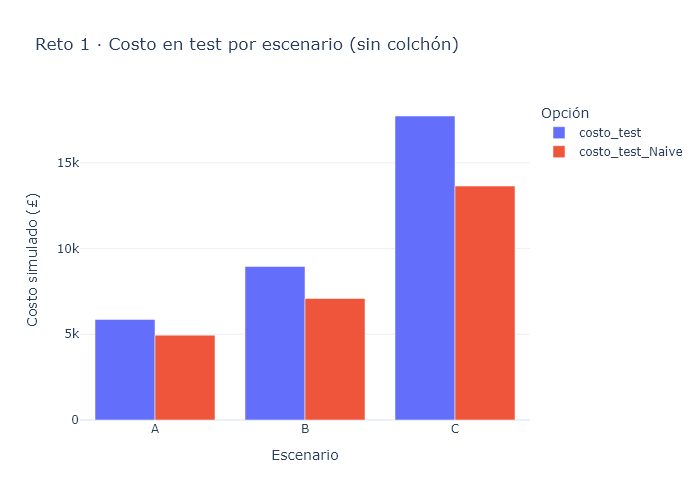

In [20]:
filas_r1c = []
for esc, (short, over) in ESCENARIOS.items():
    m = r1_eleccion[esc]
    met = evaluar(test, cantidades_test[m], over=over, short=short)
    base = evaluar(test, cantidades_test["Naive"], over=over, short=short)
    ahorro = base["costo"] - met["costo"]
    filas_r1c.append({"escenario": esc, "seleccionado": m,
        "excedentes": met["unidades_excedentes"], "faltantes": met["unidades_faltantes"],
        "costo_exceso": met["unidades_excedentes"] * over,
        "costo_faltante": met["unidades_faltantes"] * short,
        "costo_test": met["costo"], "costo_test_Naive": base["costo"],
        "diferencia_vs_Naive": ahorro,
        "ahorro_pct": 100 * ahorro / base["costo"] if base["costo"] else np.nan})
tabla_r1c = pd.DataFrame(filas_r1c).set_index("escenario")
display(tabla_r1c.round(2))
graf_r1c = tabla_r1c[["costo_test", "costo_test_Naive"]].reset_index().melt(
    id_vars="escenario", var_name="opcion", value_name="costo")
fig = px.bar(graf_r1c, x="escenario", y="costo", color="opcion", barmode="group",
             title="Reto 1 · Costo en test por escenario (sin colchón)",
             labels={"costo": "Costo simulado (£)", "escenario": "Escenario", "opcion": "Opción"})
fig.show()

**Lectura de la salida:**

Los tres ahorros firmados son negativos: **−£920,00, −£1.869,70 y −£4.087,00**. El gráfico muestra que el modelo seleccionado queda por encima de Naïve en A, B y C; C amplifica especialmente el costo de 5.884 faltantes.

**Interpretación 1C:**

En test los seleccionados pierden frente a Naïve en los tres escenarios. A: SeasonalNaive cuesta £5.869,50 frente a £4.949,50, sobrecosto **£920,00 (18,59 %)**. B: Exponential Smoothing cuesta £8.957,60 frente a £7.087,90, sobrecosto **£1.869,70 (26,38 %)**. C: cuesta £17.734,25 frente a £13.647,25, sobrecosto **£4.087,00 (29,95 %)**.

La barra de C crece por el precio del faltante: para el seleccionado son 5.884 × £3 = £17.652, frente a solo £82,25 de excedente. En A son 5.549 faltantes y 641 excedentes; en B/C son 5.884 y 329. Las cantidades no cambian entre B y C: cambia su valoración económica. Las diferencias negativas en `diferencia_vs_Naive` representan sobrecostos, no ahorros.

### Reto 1 · Apartado D — Recomendar a abastecimiento
Redacte una recomendación para abastecimiento: ¿cambia la selección entre escenarios?, ¿qué método usaría como referencia y por qué?, ¿qué límites tiene la conclusión? Distinga el ahorro simulado de un beneficio real demostrado.

**Decisión 1D:**

Mantendría **Naïve como referencia de abastecimiento** bajo los tres escenarios: los métodos elegidos en validación no lo superaron en test. No cambiaría retrospectivamente el ganador de validación ni recomendaría Exponential Smoothing solo porque el faltante sea más caro. La recomendación de modelo es sensible a costos (A elige estacional; B/C, Exponential Smoothing), pero el resultado de no sustituir al baseline se mantiene. Son costos simulados con ocho semanas y tarifas supuestas; no son pérdidas contables comprobadas ni beneficios reales de una implantación. Antes de una campaña necesitaría costos reales y señales de pedidos/promoción disponibles antes de pronosticar.

## Reto 2 — ¿Conviene añadir un colchón?

**Caso.** El área comercial propone planificar unidades adicionales cada semana para reducir faltantes. Almacén advierte que el excedente también cuesta: espacio, capital inmovilizado y posibles liquidaciones. Se debe decidir con evidencia si conviene añadir un colchón al pronóstico.

**Problema.** ¿Qué política de cantidad, sin colchón o con colchón de 0,5; 1 o 1,5 veces el MAE previo, debería usarse, y qué costo produjo en test frente a no usar colchón?

**Datos, supuestos y recursos**
- Modelo seleccionado en la parte guiada (`SELECCIONADO`) y sus pronósticos de validación y test.
- Colchón = ⌈multiplicador × MAE previo⌉; el MAE previo usa solo los 2 bloques de 8 semanas anteriores a cada origen (`mae_previo`, `colchon`, `comparar_politicas`).
- Costos base: £1,50 por faltante y £0,40 por exceso (supuestos académicos). Regla común de selección.

**Apartados**
- **A.** Definir pronóstico, cantidad planificada y políticas
- **B.** Comparar las políticas en validación
- **C.** Seleccionar el multiplicador y evaluarlo en test
- **D.** Recomendar sobre el colchón

**Evidencias que deben quedar en el notebook**
- Tabla del MAE previo y del colchón de cada política por fold.
- Costos por fold y resumen por política con excedentes, faltantes y folds en que el colchón mejoró, más el gráfico de excedentes y faltantes.
- Tabla de test de la política seleccionada frente a la opción sin colchón.
- Interpretaciones A–D.

### Reto 2 · Apartado A — Definir pronóstico, cantidad planificada y políticas
Explique la diferencia entre pronóstico y cantidad planificada. Calcule, para cada fold, el MAE previo (solo con semanas anteriores a su origen) y el colchón que tendría cada política (0; 0,5; 1 y 1,5 × MAE previo).

In [21]:
filas_r2a = []
for k, o in enumerate(origenes, 1):
    mae_k = mae_previo(SELECCIONADO, train.iloc[:o], f"reto2 preparación · fold {k}")
    for mult in MULTIPLICADORES:
        filas_r2a.append({"fold": k, "origen": train.index[o].date(),
                         "ultima_semana_calibracion": train.index[o-1].date(),
                         "MAE_previo": mae_k, "multiplicador": mult, "colchon": colchon(mult, mae_k)})
r2_prep = pd.DataFrame(filas_r2a)
assert (r2_prep["ultima_semana_calibracion"] < r2_prep["origen"]).all()
display(r2_prep.round(2))

,fold,origen,ultima_semana_calibracion,MAE_previo,multiplicador,colchon
0,1,2011-01-03,2010-12-27,1390.88,0.0,0
1,1,2011-01-03,2010-12-27,1390.88,0.5,696
2,1,2011-01-03,2010-12-27,1390.88,1.0,1391
3,1,2011-01-03,2010-12-27,1390.88,1.5,2087
4,2,2011-02-28,2011-02-21,1523.44,0.0,0
5,2,2011-02-28,2011-02-21,1523.44,0.5,762
6,2,2011-02-28,2011-02-21,1523.44,1.0,1524
7,2,2011-02-28,2011-02-21,1523.44,1.5,2286
8,3,2011-04-25,2011-04-18,1274.12,0.0,0
9,3,2011-04-25,2011-04-18,1274.12,0.5,638


**Lectura de la salida:**

La tabla confirma calibración previa en los cinco orígenes. Con k = 1, los colchones pasan de **1.391 a 1.524, 1.275, 900 y 822 unidades**; cambian con los errores anteriores, no con el error futuro que se intenta cubrir.

**Interpretación 2A:**

El pronóstico es la estimación del modelo; la cantidad planificada añade `ceil(k × MAE_previo)`. Para los folds 1–5 los MAE previos son **1.390,88; 1.523,44; 1.274,12; 899,94 y 821,81**. Por ejemplo, en el fold 1 k = 0; 0,5; 1; 1,5 genera colchones de **0, 696, 1.391 y 2.087 unidades semanales**. Se calculan con errores de bloques anteriores al 03/01/2011, no con sus ocho semanas futuras. La tabla muestra que el tamaño del colchón se adapta al origen; k fija la regla, no una cantidad constante para toda la historia.

### Reto 2 · Apartado B — Comparar las políticas en validación
Evalúe las cuatro políticas en los folds de validación con calibración temporal (`comparar_politicas`). Presente el costo por fold, el resumen por política (costo promedio, desviación, excedentes y faltantes), cuántos folds mejoró cada colchón frente a no usarlo y un gráfico de excedentes y faltantes.

Costo por fold (£):


multiplicador,0.0,0.5,1.0,1.5
fold,,,,
1,6567.0,7471.8,8514.0,10741.2
2,6713.4,5348.0,5542.5,7678.8
3,4286.6,4563.1,5664.8,7703.2
4,2537.2,3977.2,5417.2,6857.2
5,1458.6,1911.2,3226.4,4541.6


Resumen de 40 semanas de validación:


,costo_prom,costo_sd,MAE_prom,MAE_sd,RMSE_prom,WAPE_prom,excedentes,faltantes,complejidad,folds_mejora_vs_0
multiplicador,,,,,,,,,,
0.0,4312.56,2352.88,898.32,465.13,1030.27,1.24,29397.0,6536.0,0,0
0.5,4654.26,2025.52,1285.68,543.19,1432.18,1.80,48972.0,2455.0,1,1
1.0,5672.98,1880.14,1761.88,589.00,1938.93,2.46,70316.0,159.0,2,1
1.5,7504.40,2221.70,2345.12,694.28,2485.28,3.23,93805.0,0.0,3,0


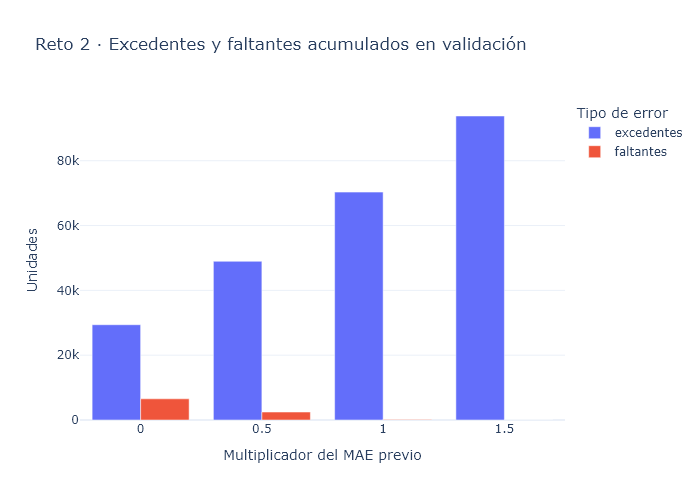

In [22]:
r2_folds = comparar_politicas(etiqueta="reto2 validación")
r2_resumen = resumir(r2_folds, "multiplicador", MULTIPLICADORES)
r2_costos = r2_folds.pivot(index="fold", columns="multiplicador", values="costo")
r2_resumen["folds_mejora_vs_0"] = [(r2_costos[m] < r2_costos[0]).sum() for m in MULTIPLICADORES]
print("Costo por fold (£):")
display(r2_costos.round(2))
print("Resumen de 40 semanas de validación:")
display(r2_resumen.round(2))
graf_r2 = r2_resumen[["excedentes", "faltantes"]].reset_index().melt(
    id_vars="multiplicador", var_name="error", value_name="unidades")
fig = px.bar(graf_r2, x="multiplicador", y="unidades", color="error", barmode="group",
             title="Reto 2 · Excedentes y faltantes acumulados en validación",
             labels={"multiplicador": "Multiplicador del MAE previo", "unidades": "Unidades", "error": "Tipo de error"})
fig.show()

**Lectura de la salida:**

El gráfico evidencia el intercambio: de k = 0 a 1,5 los faltantes bajan de **6.536 a cero**, pero los excedentes suben de **29.397 a 93.805**. k = 0,5 y k = 1 mejoran solo un fold; k = 1,5 no mejora ninguno. El costo medio mínimo corresponde a no añadir colchón.

**Interpretación 2B:**

Añadir colchón reduce faltantes y aumenta excedentes. Sin colchón: **29.397 excedentes, 6.536 faltantes y £4.312,56 de costo medio**. Con k = 0,5: 48.972 excedentes, 2.455 faltantes y £4.654,26; con k = 1: 70.316, 159 y £5.672,98; con k = 1,5: 93.805, cero y £7.504,40. Eliminar todos los faltantes no minimiza el costo.

El colchón 0,5 mejora solo el fold 2 (£5.348,00 frente a £6.713,40); k = 1 también mejora solo ese fold; k = 1,5 no mejora ninguno. La desviación de costo baja a £1.880,14 con k = 1, pero su mayor costo medio impide seleccionarlo. La regla elige k = 0, sin usar test para justificar la elección.

### Reto 2 · Apartado C — Seleccionar el multiplicador y evaluarlo en test
Seleccione el multiplicador con la regla común (sin mirar el test). Calcule el colchón del test con el MAE previo del entrenamiento y evalúe la política seleccionada frente a la opción sin colchón: costo, excedentes y faltantes. Compruebe si coincide con la política fijada en la sección 10.

In [23]:
r2_mult = seleccionar(r2_resumen)  # solamente validación; no se reselecciona usando test
mae_t = mae_previo(SELECCIONADO, train, "reto2 calibración test")
r2_colchon_test = colchon(r2_mult, mae_t)
assert r2_mult == MULT and r2_colchon_test == COLCHON_TEST
tabla_r2c = pd.DataFrame({
    "Sin colchón": evaluar(test, cantidades_test[SELECCIONADO]),
    "Política fijada": evaluar(test, cantidades_test[SELECCIONADO] + r2_colchon_test)
}).T
tabla_r2c["ahorro_vs_sin_colchon"] = tabla_r2c.loc["Sin colchón", "costo"] - tabla_r2c["costo"]
tabla_r2c["ahorro_pct"] = 100 * tabla_r2c["ahorro_vs_sin_colchon"] / tabla_r2c.loc["Sin colchón", "costo"]
display(tabla_r2c.round(2))
print(f"Multiplicador = {r2_mult:g}; MAE previo = {mae_t:.4f}; colchón = {r2_colchon_test} unidades.")
print("Coincide con la política de la sección 10: sí.")

,MAE,RMSE,WAPE,unidades_excedentes,unidades_faltantes,costo,ahorro_vs_sin_colchon,ahorro_pct
Sin colchón,776.62,1700.86,0.54,329.0,5884.0,8957.6,0.0,0.0
Política fijada,776.62,1700.86,0.54,329.0,5884.0,8957.6,0.0,0.0


Multiplicador = 0; MAE previo = 546.3125; colchón = 0 unidades.
Coincide con la política de la sección 10: sí.


**Lectura de la salida:**

Ambas filas coinciden porque el multiplicador seleccionado es cero. Costo **£8.957,60**, 329 excedentes y 5.884 faltantes; el ahorro frente a la misma opción sin colchón es cero. La política reproduce exactamente la sección 10.

**Interpretación 2C:**

El multiplicador elegido vuelve a ser **0**, con MAE previo del entrenamiento **546,3125** y colchón de **0 unidades**. Las dos filas representan por tanto la misma cantidad: ambas cuestan **£8.957,60**, con 329 excedentes y 5.884 faltantes. La diferencia es **£0,00 (0 %)** frente a no usar colchón. La coincidencia está comprobada mediante `assert`. Esto no demuestra que cualquier colchón posible sea inútil: muestra que entre las cuatro políticas y con la calibración predefinida ganó no añadirlo; no se reabre la selección usando test.

### Reto 2 · Apartado D — Recomendar sobre el colchón
Recomiende si corresponde añadir colchón y fundamente con la validación. Explique por qué la cantidad objetivo semanal no equivale automáticamente a una cantidad a comprar (inventario utilizable, pedidos que llegarán a tiempo y arrastre entre semanas).

**Decisión 2D:**

**No añadiría colchón bajo esta regla y estos costos**, porque todos los multiplicadores positivos incrementaron el costo medio de validación; el menor aumento, con k = 0,5, fue £341,70 por fold. Además, no adoptaría el modelo principal como sustituto de Naïve por su resultado final. Un objetivo semanal solo indica la disponibilidad buscada: para estimar una compra hay que restar inventario utilizable y pedidos que llegarán antes de necesitarse, limitar el resultado a cero y trasladar los sobrantes a la semana siguiente. La suma de objetivos no hace ese balance; el notebook no dispone de esas entradas operativas.

### Reto 2 · Ampliación opcional: ventana de calibración
Repita la comparación con 1, 2 y 3 bloques de calibración y observe si cambia el multiplicador elegido. Si muestra costos de test de las políticas descartadas, identifíquelos como retrospectivos: no se usan para cambiar la política.

In [24]:
filas_ventanas = []
for b in [1, 2, 3]:
    v_folds = comparar_politicas(bloques=b, etiqueta=f"ventana {b}")
    v_resumen = resumir(v_folds, "multiplicador", MULTIPLICADORES)
    v_mult = seleccionar(v_resumen)
    v_mae = mae_previo(SELECCIONADO, train, f"ventana {b} calibración", bloques=b)
    filas_ventanas.append({"bloques": b, "semanas_calibracion": b * BT_H,
                          "multiplicador_elegido": v_mult,
                          "costo_prom_validacion": v_resumen.loc[v_mult, "costo_prom"],
                          "costo_sd": v_resumen.loc[v_mult, "costo_sd"],
                          "MAE_previo_al_test": v_mae, "colchon_al_test": colchon(v_mult, v_mae)})
ventanas = pd.DataFrame(filas_ventanas).set_index("bloques")
display(ventanas.round(2))
print("Sensibilidad exploratoria de validación: se mantiene la regla original de 2 bloques y el multiplicador fijado.")

,semanas_calibracion,multiplicador_elegido,costo_prom_validacion,costo_sd,MAE_previo_al_test,colchon_al_test
bloques,,,,,,
1,8,0.0,4312.56,2352.88,299.75,0
2,16,0.0,4312.56,2352.88,546.31,0
3,24,0.0,4312.56,2352.88,647.79,0


Sensibilidad exploratoria de validación: se mantiene la regla original de 2 bloques y el multiplicador fijado.


**Lectura de la salida:**

Cambiar de uno a tres bloques modifica el MAE de calibración, pero en las tres comparaciones gana **k = 0**. Esta sensibilidad apoya la regla de no añadir colchón dentro de las ventanas ensayadas y mantiene la especificación original de dos bloques.

**Comentario opcional 2:**

Con ventanas de **8, 16 y 24 semanas** se selecciona siempre k = 0, con el mismo costo medio £4.312,56 y desviación £2.352,88. El MAE previo al test sí cambia: **299,75; 546,31 y 647,79**, respectivamente; al multiplicarlo por cero, el colchón sigue en cero. La decisión de no añadir colchón es estable dentro de estas ventanas ensayadas, no una propiedad universal del producto. La ampliación es exploratoria y se conserva la regla principal de dos bloques; no se elige una ventana mirando costos de test.

## Reto 3 — ¿Funciona la misma solución para otro producto?

**Caso.** La empresa quiere extender el procedimiento a un segundo producto de alta rotación antes de aplicarlo a toda la cartera. La gerencia pregunta si el método que se eligió para el primer producto puede generalizarse.

**Problema.** ¿Qué modelo se selecciona para el segundo producto con las mismas reglas, cómo le fue en test frente a Naïve y qué haría la empresa con cada producto?

**Datos, supuestos y recursos**
- Segundo SKU de la lista de elegibles, definida solo con el entrenamiento (no se elige mirando el test).
- Mismas semanas completas, limpieza, backtesting, costos base y regla común de selección.
- Se comparan modelos **sin colchón** para mantener el alcance claro; la política de colchón se trabajó en el Reto 2.

**Apartados**
- **A.** Identificar el producto y describir su serie
- **B.** Backtesting y selección con la regla común
- **C.** Evaluar en test y comparar ambos productos
- **D.** Recomendación consolidada

**Evidencias que deben quedar en el notebook**
- Serie del segundo producto y tabla descriptiva del entrenamiento frente al primero, con su gráfico.
- Tabla de backtesting por modelo y seleccionado.
- Tabla comparativa de ambos productos con modelo, costos, ahorro o sobrecosto y resultado.
- Interpretaciones A–D.

### Reto 3 · Apartado A — Identificar el producto y describir su serie
Identifique el segundo SKU elegible, construya su serie con las mismas semanas completas y separe entrenamiento y test. Describa su comportamiento solo con el entrenamiento y compárelo con el primer producto (tabla y gráfico).

Segundo SKU: 85123A · WHITE HANGING HEART T-LIGHT HOLDER


,count,mean,std,min,25%,50%,75%,max,semanas_cero,unidades_train
84077,96.0,919.51,1080.36,0.0,372.5,584.5,960.0,7063.0,3,88273.0
85123A,96.0,842.74,582.80,0.0,442.0,718.5,1025.5,3329.0,2,80903.0


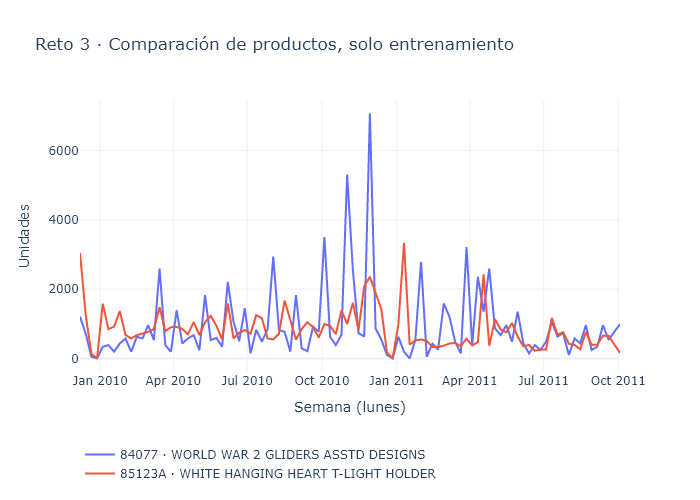

In [25]:
assert len(elegibles) >= 2, "Se necesita un segundo SKU elegible"
SKU2 = elegibles.loc[1, "StockCode"]
desc2 = uk_train.loc[uk_train["StockCode"] == SKU2, "Description"].dropna().astype(str).mode().iloc[0]
serie2 = (uk[uk["StockCode"] == SKU2].groupby("week")["Quantity"].sum()
          .reindex(semanas, fill_value=0).astype(float))
serie2.name = "unidades"
train2, test2 = serie2.loc[semanas_train], serie2.loc[semanas_test]
r3_desc = pd.DataFrame({SKU: train.describe(), SKU2: train2.describe()}).T
r3_desc["semanas_cero"] = [(s == 0).sum() for s in [train, train2]]
r3_desc["unidades_train"] = [train.sum(), train2.sum()]
print("Segundo SKU:", SKU2, "·", desc2)
display(r3_desc.round(2))
fig = go.Figure()
for s, nombre in [(train, f"{SKU} · {desc}"), (train2, f"{SKU2} · {desc2}")]:
    fig.add_trace(go.Scatter(x=s.index, y=s, name=nombre))
fig.update_layout(title="Reto 3 · Comparación de productos, solo entrenamiento",
                  xaxis_title="Semana (lunes)", yaxis_title="Unidades", legend=dict(orientation="h", y=-0.25),
                  height=500)
fig.show()

**Lectura de la salida:**

85123A acumula **80.903 unidades** de entrenamiento y tiene menor dispersión que 84077: desviación **582,80 frente a 1.080,36**. Se construye con el mismo calendario y la comparación gráfica usa solo entrenamiento, por lo que no se ha elegido el segundo producto por su resultado de test.

**Interpretación 3A:**

El segundo elegible por volumen de entrenamiento es **85123A — WHITE HANGING HEART T-LIGHT HOLDER**. Registra **80.903 unidades**, frente a 88.273 de 84077. Su media es 842,74 y mediana 718,50; su desviación 582,80 es menor que la del primer producto (1.080,36). Sus máximos son 3.329 frente a 7.063 unidades. El segundo SKU tiene dos semanas en cero y el primero tres; las dos compartidas coinciden con ausencia de registros UK generales. En términos relativos la desviación/media es aproximadamente 0,69 frente a 1,17: el segundo producto tiene una serie menos dispersa. La elección procede del ranking de entrenamiento, sin consultar el desempeño futuro.

### Reto 3 · Apartado B — Backtesting y selección con la regla común
Ejecute el mismo backtesting con Naïve, Naïve estacional y Exponential Smoothing (`backtest`), resuma los resultados y seleccione con la regla común. Presente la tabla e indique si la selección se decidió por la tolerancia del 1 %.

In [26]:
filas2, q_bt2 = backtest(train2, MODELOS, "reto3")
bt2 = pd.DataFrame(filas2)
tabla2 = resumir(filas2, "modelo", MODELOS)
SELECCIONADO2 = seleccionar(tabla2)
print("Métricas de cada fold:")
display(bt2.round(2))
print("Resumen del segundo SKU:")
display(tabla2.round(2))
limite2 = tabla2["costo_prom"].min() * 1.01
candidatos2 = tabla2.index[tabla2["costo_prom"] <= limite2 + 1e-9].tolist()
print("Seleccionado:", SELECCIONADO2, "· límite con 1 %:", round(limite2, 2), "· candidatos:", candidatos2)

Métricas de cada fold:


,MAE,RMSE,WAPE,unidades_excedentes,unidades_faltantes,costo,fold,modelo
0,864.62,1285.06,1.00,0.0,6917.0,10375.5,1,Naive
1,787.12,969.98,0.91,3174.0,3123.0,5954.1,1,SeasonalNaive
2,814.88,1015.58,0.94,4140.0,2379.0,5224.5,1,ExpSmoothing
3,351.88,749.77,0.52,0.0,2815.0,4222.5,2,Naive
4,348.12,748.21,0.51,382.0,2403.0,3757.3,2,SeasonalNaive
5,701.38,787.25,1.03,4043.0,1568.0,3969.2,2,ExpSmoothing
6,1737.75,1760.75,2.54,13902.0,0.0,5560.8,3,Naive
7,732.00,997.40,1.07,4025.0,1831.0,4356.5,3,SeasonalNaive
8,275.50,343.57,0.40,1810.0,394.0,1315.0,3,ExpSmoothing
9,239.12,334.70,0.46,433.0,1480.0,2393.2,4,Naive


Resumen del segundo SKU:


,costo_prom,costo_sd,MAE_prom,MAE_sd,RMSE_prom,WAPE_prom,excedentes,faltantes,complejidad
modelo,,,,,,,,,
Naive,4814.82,3483.34,670.62,656.73,867.66,0.97,14694.0,12131.0,0
SeasonalNaive,3306.84,2147.86,459.32,290.28,665.50,0.67,10023.0,8350.0,1
ExpSmoothing,2591.72,1907.18,475.10,266.44,569.77,0.71,14134.0,4870.0,2


Seleccionado: ExpSmoothing · límite con 1 %: 2617.64 · candidatos: ['ExpSmoothing']


**Lectura de la salida:**

Para el segundo SKU gana Exponential Smoothing con costo medio **£2.591,72** y desviación **£1.907,18**. Solo él queda por debajo del límite £2.617,64; los cinco folds resultan más baratos que Naïve. Su MAE es 475,10, ligeramente mayor que 459,32 del estacional.

**Interpretación 3B:**

Para 85123A se selecciona **Exponential Smoothing**, con costo medio **£2.591,72**, frente a £3.306,84 de SeasonalNaive y £4.814,82 de Naïve. El límite de tolerancia es **£2.617,64** y solo Exponential Smoothing entra; el 1 % no cambia el ganador. También tiene el menor RMSE medio (569,77) y menor desviación de costo (£1.907,18); SeasonalNaive conserva un MAE algo menor (459,32 frente a 475,10). Exponential Smoothing supera el costo de Naïve en los cinco folds. El ranking estadístico y el económico siguen sin ser completamente intercambiables.

### Reto 3 · Apartado C — Evaluar en test y comparar ambos productos
Evalúe en test el modelo seleccionado y Naïve para el segundo producto. Construya una tabla comparativa de ambos productos (sin colchón) con modelo seleccionado, costo de validación, costo de test del seleccionado y de Naïve, ahorro o sobrecosto, folds en que superó a Naïve y resultado de la evaluación, aplicando la regla de adopción de la sección 13.

In [27]:
# La elección del segundo producto usa exclusivamente tabla2; el test se evalúa después.
q_test2 = {m: pronosticar(m, train2, TEST_H, "reto3 test") for m in dict.fromkeys([SELECCIONADO2, "Naive"])}
res_test2 = pd.DataFrame({m: evaluar(test2, q) for m, q in q_test2.items()}).T
print("Test del segundo SKU (sin colchón):")
display(res_test2.round(2))

def decision_adopcion(costo, base, ganados):
    if costo >= base:
        return "No adoptar como sustituto de Naïve"
    return "Adoptar como piloto controlado" if ganados > len(origenes) / 2 else "Mantener en evaluación"

filas_comparacion = []
for sku, modelo, tabla_val, tabla_bt, costo_sel, costo_base in [
    (SKU, SELECCIONADO, resumen_val, bt, res_test.loc[f"{SELECCIONADO} (sin colchón)", "costo"], costo_naive),
    (SKU2, SELECCIONADO2, tabla2, bt2, res_test2.loc[SELECCIONADO2, "costo"], res_test2.loc["Naive", "costo"])
]:
    costos_fold = tabla_bt.pivot(index="fold", columns="modelo", values="costo")
    ganados = int((costos_fold[modelo] < costos_fold["Naive"]).sum())
    ahorro = costo_base - costo_sel
    filas_comparacion.append({"SKU": sku, "modelo_sin_colchon": modelo,
        "costo_prom_validacion": tabla_val.loc[modelo, "costo_prom"],
        "costo_test": costo_sel, "costo_test_Naive": costo_base,
        "ahorro_vs_Naive": ahorro, "ahorro_pct": 100 * ahorro / costo_base if costo_base else np.nan,
        "folds_ganados": ganados, "decision": decision_adopcion(costo_sel, costo_base, ganados)})
comparacion = pd.DataFrame(filas_comparacion).set_index("SKU")
display(comparacion.round(2))

Test del segundo SKU (sin colchón):


,MAE,RMSE,WAPE,unidades_excedentes,unidades_faltantes,costo
ExpSmoothing,355.25,497.68,0.50,806.0,2036.0,3376.4
Naive,554.12,717.80,0.78,8.0,4425.0,6640.7


,modelo_sin_colchon,costo_prom_validacion,costo_test,costo_test_Naive,ahorro_vs_Naive,ahorro_pct,folds_ganados,decision
SKU,,,,,,,,
84077,ExpSmoothing,4312.56,8957.6,7087.9,-1869.7,-26.38,4,No adoptar como sustituto de Naïve
85123A,ExpSmoothing,2591.72,3376.4,6640.7,3264.3,49.16,5,Adoptar como piloto controlado


**Lectura de la salida:**

El segundo SKU ahorra **£3.264,30 (49,16 %)** en test y gana cinco folds, cumpliendo la regla de piloto. El primero genera **£1.869,70 de sobrecosto (26,38 %)** y no se adopta como sustituto. Se evalúan ambos sin colchón y se mantiene cada elección de validación.

**Interpretación 3C:**

La evaluación diferencia los productos aunque seleccione el mismo modelo. Para **84077**, sin colchón, el costo es £8.957,60 frente a £7.087,90 de Naïve: sobrecosto **£1.869,70 (26,38 %)** y cuatro folds ganados; corresponde **no adoptar como sustituto**. Para **85123A**, Exponential Smoothing cuesta **£3.376,40 frente a £6.640,70**, un ahorro simulado de **£3.264,30 (49,16 %)** y cinco folds ganados; cumple la regla de **adoptar como piloto controlado**.

En el segundo SKU, reducir faltantes de 4.425 a 2.036 ahorra £3.583,50 en ese componente, mientras aumentar excedentes de 8 a 806 agrega £319,20: ahorro neto £3.264,30. La comparación del reto es sin colchón para ambos; no calibra una política de colchón del segundo producto.

### Reto 3 · Apartado D — Recomendación consolidada
Prepare una recomendación para la empresa: qué haría con cada producto (adoptar, mantener en evaluación o no adoptar), qué evidencia la respalda y por qué dos productos no permiten generalizar el método a toda la cartera.

**Decisión 3D:**

Para **84077**, mantendría Naïve como referencia y continuaría investigando señales de grandes pedidos antes de sustituirlo. Para **85123A**, iniciaría un **piloto controlado de Exponential Smoothing sin colchón**, preservando Naïve como comparador: hay ahorro de 49,16 % en test y mejora en cinco de cinco folds. En semanas nuevas comprobaría el costo acumulado y por bloque antes de ampliar su uso; sin inventario y plazos reales no emitiría compras desde esta tabla. Dos SKUs de alta rotación, seleccionados de una lista de 389 elegibles, no representan toda la cartera ni a productos intermitentes: hacen falta más SKUs, estaciones y periodos prospectivos para generalizar.

### Revisión de advertencias y verificaciones automáticas

Se resumen las advertencias de **todos** los ajustes de Exponential Smoothing (backtesting, calibración, test, reentrenamiento final y retos) y se comprueban las condiciones de validez del flujo.

In [28]:
aj = pd.DataFrame(registro_ajustes)
display(aj.groupby("etapa").agg(ajustes=("ajuste", "count"), con_advertencias=("advertencias", lambda s: int((s > 0).sum())),
                                tipos=("tipos", lambda s: "; ".join(sorted({t for x in s for t in x.split("; ") if t}))))
          .sort_values("ajustes", ascending=False))
mensajes = sorted({m for x in aj["mensajes"] for m in x.split(" | ") if m})
print("Mensajes distintos:", mensajes if mensajes else "ninguno")
print("Especificaciones usadas:", aj["especificacion"].value_counts().to_dict())

verificaciones = {
    "Ningún fold invade el test": all(train.index[o + BT_H - 1] < semanas_test[0] for o in origenes),
    "Colchón de cada fold calibrado solo con semanas anteriores a su origen": bool((pol_folds["ultima_semana_calibracion"] < pol_folds["inicio_validacion"]).all()),
    "Colchón del test calculado solo con el entrenamiento": len(train) == len(semanas_train) and train.index[-1] < semanas_test[0],
    "La tabla final usa el multiplicador fijado": COLCHON_FINAL == colchon(MULT, MAE_FINAL),
    "El costo de la política en test se recalcula con su colchón": np.isclose(costo_pol, evaluar(test, q_politica)["costo"]),
}
for k, v in verificaciones.items():
    print(("OK   " if v else "FALLA"), k)
verificaciones.update({
    "104 semanas: 96 entrenamiento y 8 test": len(serie) == 104 and len(train) == 96 and len(test) == 8,
    "Cinco folds y horizonte de ocho semanas": len(origenes) == 5 and BT_H == TEST_H == 8,
    "SKU seleccionado solo con entrenamiento": SKU == elegibles.iloc[0]["StockCode"],
    "Segundo SKU elegido por ranking de entrenamiento": SKU2 == elegibles.iloc[1]["StockCode"],
    "Reto 2 reproduce la política fijada": r2_mult == MULT and r2_colchon_test == COLCHON_TEST,
    "Cantidades no negativas e indivisibles": all(np.all(q >= 0) and np.all(q == np.round(q)) for q in cantidades_test.values()),
    "Costo = exceso × 0.40 + faltante × 1.50": np.isclose(costo_pol, res_test.loc[fila_pol, "unidades_excedentes"] * OVER_COST + res_test.loc[fila_pol, "unidades_faltantes"] * SHORT_COST),
})
print("\nAuditoría completa:")
for nombre, ok in verificaciones.items():
    print("OK" if ok else "FALLA", "·", nombre)
assert all(verificaciones.values()), "Revisar condiciones de validez"


,ajustes,con_advertencias,tipos
etapa,,,
ventana 3,15,0,
ventana 2,10,0,
calibración,10,0,
reto2 validación,10,0,
reto2 preparación,10,0,
backtesting,5,0,
ventana 1,5,0,
reto3,5,0,
ventana 3 calibración,3,0,


Mensajes distintos: ninguno
Especificaciones usadas: {'nivel + tendencia + estacionalidad aditivas (m = 4)': 85}
OK    Ningún fold invade el test
OK    Colchón de cada fold calibrado solo con semanas anteriores a su origen
OK    Colchón del test calculado solo con el entrenamiento
OK    La tabla final usa el multiplicador fijado
OK    El costo de la política en test se recalcula con su colchón

Auditoría completa:
OK · Ningún fold invade el test
OK · Colchón de cada fold calibrado solo con semanas anteriores a su origen
OK · Colchón del test calculado solo con el entrenamiento
OK · La tabla final usa el multiplicador fijado
OK · El costo de la política en test se recalcula con su colchón
OK · 104 semanas: 96 entrenamiento y 8 test
OK · Cinco folds y horizonte de ocho semanas
OK · SKU seleccionado solo con entrenamiento
OK · Segundo SKU elegido por ranking de entrenamiento
OK · Reto 2 reproduce la política fijada
OK · Cantidades no negativas e indivisibles
OK · Costo = exceso × 0.40 + f

**Lectura de la salida:**

Se registraron **85 ajustes de Exponential Smoothing**, todos con nivel, tendencia y estacionalidad aditivos m = 4, y **ninguno produjo advertencias de ajuste**. Las **12 verificaciones** del flujo pasan. Las advertencias de `pip` y de fechas vistas antes pertenecen al entorno; este resumen se refiere específicamente a los ajustes. La auditoría confirma consistencia del procedimiento, no rentabilidad futura ni calidad de inventario no observado.

### Retroalimentación final

**Pregunta 10.** Indique dos razones por las que el modelo podría fallar en producción aun cuando el backtesting haya sido bueno.

**Respuesta:**

1. **Pedidos extraordinarios no anticipados:** en la semana del 24/10/2011 una factura aporta 4.800 unidades. El modelo univariante no conoce campañas, pedidos pactados ni clientes mayoristas; una variación así puede superar ampliamente el nivel aprendido aunque el costo haya sido favorable en cuatro de cinco folds.
2. **Ventas registradas que ocultan la demanda real:** la semana del 17/01/2011 tiene cero ventas del SKU con otros registros UK presentes. Si hubo falta de inventario, aprender ese cero como demanda nula sesga el pronóstico. Sin inventario, quiebres de stock, plazos de reposición y costos reales no puede garantizarse que un buen backtesting reduzca el costo operativo real.

# 15. Ticket de salida

**Respuesta:**

El modelo seleccionado antes del test fue **Exponential Smoothing**, con la política **k = 0 × MAE previo** (costo promedio de validación **£4.312,56**). En el test costó **£8.957,60** frente a **£7.087,90** de Naïve. Mi decisión es **no adoptar como sustituto de Naïve** porque produjo un **sobrecosto de £1.869,70 (26,38 %)**, aunque ganó cuatro de cinco folds. La proyección académica de **9.291 unidades**, suma de ocho objetivos semanales históricos, no es una orden de compra porque no descuenta inventario utilizable ni pedidos a tiempo, y no simula el arrastre del excedente entre semanas.

# 16. Conclusiones

1. **La calidad y el orden temporal cambian el problema.** Se parte de 1.067.371 transacciones, se delimitan 958.501 líneas UK válidas y se conservan 104 semanas completas. SKU, modelo y colchón se seleccionan sin test; las dos semanas sin registros generales y el cero adicional de 84077 no prueban demanda nula ni disponibilidad.
2. **Menor costo de validación no garantiza adopción.** Para 84077, Exponential Smoothing sin colchón cuesta £4.312,56 por fold en promedio y gana cuatro de cinco, pero genera £1.869,70 de sobrecosto (26,38 %) en test. No se adopta como sustituto. La ventaja de añadir colchón tampoco se observa: k = 0 resulta seleccionado con ventanas de uno, dos y tres bloques.
3. **La decisión debe evaluarse por producto y con condiciones operativas reales.** En 85123A el mismo modelo reduce el costo simulado £3.264,30 (49,16 %) y gana cinco folds, justificando un piloto. Esa evidencia no acredita beneficios reales en toda la cartera. La proyección histórica de 9.291 unidades para 84077 es una suma de objetivos semanales, no una compra ni una recomendación para 2026.


# 17. Evidencia de entrega

- [x] Fuente, hojas, dimensiones, rango de fechas y versiones visibles.
- [x] Limpieza documentada (incluidos `StockCode` nulos).
- [x] Semanas de lunes a domingo; semanas incompletas excluidas.
- [x] Test de 8 semanas reservado antes de seleccionar el SKU, el modelo y la política.
- [x] SKU seleccionado con criterios previos al test y límites del criterio de disponibilidad explicados.
- [x] Exploración solo con entrenamiento.
- [x] Backtesting de 8 semanas con fechas de cada fold y comprobación de que no invade el test.
- [x] Regla única de selección aplicada a modelo, política y retos.
- [x] Colchón calibrado solo con errores previos a cada origen.
- [x] Política fijada antes del test y evaluada una vez.
- [x] Decisión de adopción separada de la proyección académica.
- [x] Tres retos individuales con sus apartados A, B, C y D resueltos e interpretados; advertencias revisadas.
- [x] Notebook ejecutado en GitHub (`semana10/`): [archivo](https://github.com/jhadir08/analitica-empresarial-integrada/blob/main/semana10/LAB-D10-AEI-PSAYAN-2026-02_YUPANQUI.ipynb).
- [x] Enlace de apertura de esa versión en [Colab](https://colab.research.google.com/github/jhadir08/analitica-empresarial-integrada/blob/main/semana10/LAB-D10-AEI-PSAYAN-2026-02_YUPANQUI.ipynb).
- [ ] Copia personal en Drive y presentación de ambos enlaces en Canvas: fuera del alcance solicitado; no se registra como realizada.
- [x] Uso de IA declarado.

# Referencias
- Chen, D. (2012). *Online Retail II* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5CG6D
- Hyndman, R. J., & Athanasopoulos, G. (2021). *Forecasting: Principles and Practice* (3rd ed.). OTexts.
- Sharda, R., Delen, D., & Turban, E. *Business Intelligence, Analytics, Data Science and AI*. Pearson.

**Material consultado:** PPT-S10-AEI-PSAYAN-2026-02.pdf (38 diapositivas) y plantilla original LAB-D10-AEI-PSAYAN-2026-02-ESTUDIANTE.ipynb. Los ejemplos de la presentación se usan para conceptos; las conclusiones numéricas se toman de las salidas ejecutadas de este notebook.

**Reproducción:** ejecutar las celdas en orden. Se descarga el ZIP oficial de UCI y se concatenan sus dos hojas. Las versiones efectivas aparecen al inicio; se ejecutó con Plotly 5.24.1, openpyxl 3.1.5 y ucimlrepo 0.0.7. Los PNG están incrustados para revisión en GitHub. Si no hay Kaleido, el código usa la salida interactiva de Plotly. No se requieren rutas locales de esta computadora.
